> **Status (2026-10-09).** All cells were re-run on the **2026 cohort** (canonical blocks 1–4),
> with the SNR-0.2/0.6 bias correction and the rebuilt `RRMats.mat` (new `CP_BOUNDS` grid).
> The *interpretation* markdown in Sections 1–5 (and the Background numbers above) was written
> for the earlier run on the superseded **2025 cohort** and has not yet been updated; trust the
> printed outputs, not those cells' numbers. Sections 6–8 are Ishan's; Section 9 is new.

# Change-Point Exploratory Analyses

## Background

Figure 06 characterizes how participants adjust their decision bounds in response to a
mid-trial **change point (CP)** in SNR (Low→High or High→Low). In CP trials the SNR
shifts at a specific step within each trial; the pre-CP bound and post-CP bound are
estimated separately from the portions of trials before and after that step. The main
findings were:

- Participants in the **LowHigh** direction do increase their bounds post-CP (Wilcoxon p ≈ 0.02),
  and LowHigh post-CP bounds are higher than HighLow post-CP bounds (p = 0.006).
- Participants in the **HighLow** direction show no significant bound change post-CP (p ≈ 0.54).
- The RR-gradient vs. bound-change scatter (Figure 06, Row 2) shows modest Spearman correlations.

Overall the effects are variable across participants and weak. This notebook explores two
additional analyses that may reveal more robust structure:

1. **Bound change vs. CP timing** — the step at which the CP occurs varies across subjects.
   Subjects whose CP occurs earlier in the trial have more steps remaining at the new SNR,
   giving more opportunity to benefit from (and therefore to learn) the optimal post-CP bound.
   If adaptation is occurring, earlier CP steps should predict larger bound changes.

2. **Combined gradient + CP timing** — the RR gradient (benefit of adjusting the bound toward
   optimal) and the CP step are in principle independent predictors of bound adjustment. We
   examine whether they each contribute unique variance and whether their effects interact.

## Data

Same data as Figure 06:
- Per-subject pre-/post-CP bounds and stable-SNR bounds, computed directly from raw data
  (`get_data_table` + `pigeon.data.get_bound_summaries_wcp`), not loaded
  from a cached `.mat` file.
- `RRMats.mat` — reward-rate matrices for computing per-subject gradients (still a
  pre-computed file, since it takes hours to simulate).

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import scipy.io
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table
from pigeon.data import get_bound_summaries_wcp
from pigeon.pathDefaults import BIAS_CORRECTION_CP_FILE, RR_MATS_FILE

TITLES = ['LowHigh', 'HighLow']

In [2]:
# ── Load data ──────────────────────────────────────────────────────────────────
# Computed directly from raw data (fast -- seconds), not loaded from a cached
# .mat file. Matches Figure06_cpSummary.ipynb.
_data_table_mxsc = get_data_table(
    task_type='MXSC',
    combine_snr=False, correct_bias=BIAS_CORRECTION_CP_FILE,
)
_bound_summaries = get_bound_summaries_wcp(_data_table_mxsc)

lh_bounds = np.asarray(_bound_summaries['LowHigh'])    # (n_subjects, 2): col 0 = pre-CP, col 1 = post-CP
hl_bounds = np.asarray(_bound_summaries['HighLow'])
lo_bounds = np.asarray(_bound_summaries['Low'])        # stable Low-SNR block bounds (n_subjects, 2)
hi_bounds = np.asarray(_bound_summaries['High'])       # stable High-SNR block bounds
cp_lh     = np.asarray(_bound_summaries['CPLowHigh'])  # per-subject CP step (within-trial step at which SNR shifts), LowHigh
cp_hl     = np.asarray(_bound_summaries['CPHighLow'])  # same for HighLow

# load_cp_rr_mats refuses a file built for a different task design or missing CP steps.
from pigeon.data import load_cp_rr_mats
rr_mat = load_cp_rr_mats(RR_MATS_FILE, _data_table_mxsc)

# Bound grid the RR matrix was actually built with (Make_RRMatrix.ipynb's
# CP_BOUNDS) -- loaded from the file rather than hardcoded, since it is a
# non-uniform, CP-scale-specific grid, not the uniform 0.01:0.05:0.8 grid
# used for the unrelated MX matrix.
BOUNDS = np.atleast_1d(rr_mat['bounds']).astype(float)
pmats  = list(rr_mat['pmats'].flat)  # [LowHigh pmat, HighLow pmat]
                                      # each: (n_bounds × n_bounds × n_cp_steps)

# Use the CP step arrays from the mat file when available (saved by Make_RRMatrix.ipynb
# with cp_steps_lh / cp_steps_hl; old format used a single cp_steps field).
# These are the exact CP steps the matrix was built for, so each subject's CP step
# maps to an exact 3rd-axis index with no nearest-neighbor approximation.
if 'cp_steps_lh' in rr_mat and 'cp_steps_hl' in rr_mat:
    cp_times = [rr_mat['cp_steps_lh'], rr_mat['cp_steps_hl']]
else:
    cp_times = [np.unique(cp_lh), np.unique(cp_hl)]

# Finite-data masks (exclude subjects with missing bounds)
lh_ok = np.isfinite(lh_bounds[:, 0]) & np.isfinite(lh_bounds[:, 1])
hl_ok = np.isfinite(hl_bounds[:, 0]) & np.isfinite(hl_bounds[:, 1])

print(f'LowHigh: {lh_ok.sum()} subjects with finite bounds')
print(f'HighLow: {hl_ok.sum()} subjects with finite bounds')
print(f'CP step LowHigh: range {np.nanmin(cp_lh):.0f}–{np.nanmax(cp_lh):.0f}, '
      f'median {np.nanmedian(cp_lh):.1f}')
print(f'CP step HighLow: range {np.nanmin(cp_hl):.0f}–{np.nanmax(cp_hl):.0f}, '
      f'median {np.nanmedian(cp_hl):.1f}')
print(f'Matrix LowHigh CP steps ({len(cp_times[0])}): {cp_times[0][0]}–{cp_times[0][-1]}')
print(f'Matrix HighLow CP steps ({len(cp_times[1])}): {cp_times[1][0]}–{cp_times[1][-1]}')

LowHigh: 50 subjects with finite bounds
HighLow: 55 subjects with finite bounds
CP step LowHigh: range 3–25, median 12.0
CP step HighLow: range 3–20, median 7.0
Matrix LowHigh CP steps (20): 3–25
Matrix HighLow CP steps (14): 3–20


/Users/jigold/.cache/uv/archive-v0/Tz1O9i1auCqkh_VB/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


---
## Section 1 — Bound change vs. CP timing

**Rationale**: In CP trials the SNR shifts at a specific within-trial step. The step at which
this occurs varies across subjects. Subjects whose CP step is early have more steps remaining
in the trial at the new SNR, so they accumulate more evidence under the new regime and have
more opportunity to benefit from — and therefore to learn — an adjusted post-CP bound.
Subjects whose CP step is late have few remaining steps; the benefit of adjusting the bound
is smaller, so there is less incentive to do so.

If participants are dynamically adjusting their bounds, earlier CP steps should predict
larger bound changes (in the appropriate direction for each condition).

For **LowHigh** the optimal adjustment is an *increase* in bound (moving from Low-SNR to
High-SNR optimal). For **HighLow** the optimal adjustment is a *decrease*. We plot raw
bound change (post − pre) for each direction; the sign of a "correct" adjustment therefore
differs between panels.

Statistics: Spearman rank correlation (robust to outliers and monotone non-linear
relationships) with a least-squares regression line for visual reference.

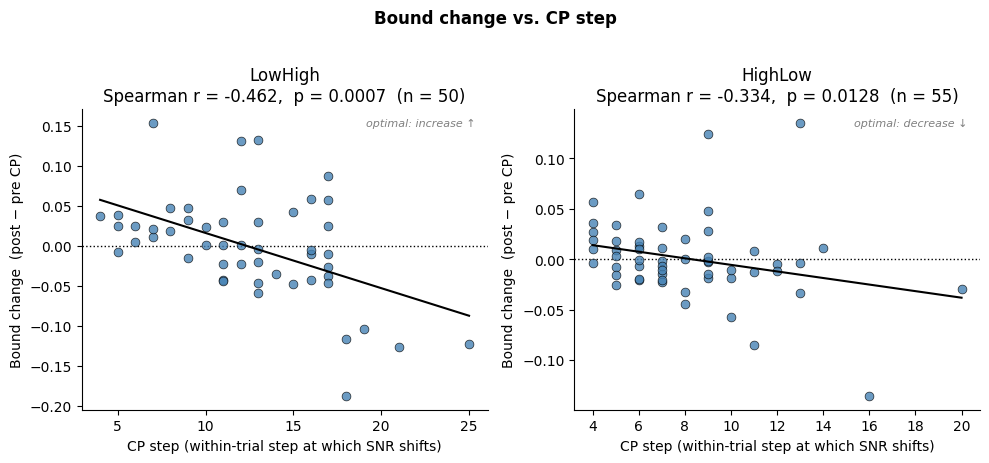

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharey=False)

for tt, (ax, ok, bounds_arr, cpt, title) in enumerate(zip(
        axs,
        [lh_ok, hl_ok],
        [lh_bounds, hl_bounds],
        [cp_lh, cp_hl],
        TITLES)):

    delta = bounds_arr[ok, 1] - bounds_arr[ok, 0]  # post − pre CP bound change
    cpt_ok = cpt[ok]

    # ── Spearman correlation ───────────────────────────────────────────────────
    r, p = scipy.stats.spearmanr(cpt_ok, delta)

    # ── OLS regression line (for visual reference only; stats from Spearman) ──
    slope, intercept = np.polyfit(cpt_ok, delta, 1)
    x_line = np.linspace(cpt_ok.min(), cpt_ok.max(), 100)

    # ── Plot ──────────────────────────────────────────────────────────────────
    ax.axhline(0, color='k', linestyle=':', linewidth=1, zorder=0)  # no-change reference
    ax.scatter(cpt_ok, delta, color='steelblue', edgecolors='k',
               linewidths=0.5, s=40, zorder=2, alpha=0.8)
    ax.plot(x_line, slope * x_line + intercept, 'k-', linewidth=1.5, zorder=3)

    # ── Labels and stats ──────────────────────────────────────────────────────
    ax.set_xlabel('CP step (within-trial step at which SNR shifts)')
    ax.set_ylabel('Bound change  (post − pre CP)')
    p_str = f'{p:.4f}' if p >= 0.0001 else f'{p:.2e}'
    ax.set_title(f'{title}\nSpearman r = {r:.3f},  p = {p_str}  (n = {ok.sum()})')

    # Annotate direction of optimal adjustment so readers can interpret sign of y-axis
    opt_dir = 'optimal: increase ↑' if tt == 0 else 'optimal: decrease ↓'
    ax.text(0.97, 0.97, opt_dir, transform=ax.transAxes,
            ha='right', va='top', fontsize=8, color='gray', style='italic')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Bound change vs. CP step', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Section 1 interpretation

A negative Spearman r means that subjects with earlier CPs (smaller step number, more
remaining steps at the new SNR) show larger bound changes in the positive direction.
For LowHigh this is the correct direction (bound should increase), so a negative r is
consistent with time-dependent adaptation.

For HighLow, where the bound should *decrease*, the logic is the same but the sign of
the correlation differs: earlier CP → more negative Δbound → as x increases y increases
(becomes less negative) → a *positive* r would indicate that earlier CPs go with larger
decreases, consistent with time-dependent adaptation.

---
## Section 2 — Combined gradient + CP timing

**Rationale**: The Figure 06 Row-2 analysis regresses bound change on the *RR gradient* —
the slope of the reward-rate surface from the subject's pre-CP bound toward the optimal
post-CP bound. A steeper gradient means more to gain from adjusting. The CP step is a
separate factor: given the same incentive, subjects with more steps remaining at the new
SNR (earlier CP step) should have more opportunity to benefit from adjusting their bound.

Here we ask:
1. How correlated are the gradient and the CP step with each other? (Are they confounded?
   Note that the gradient is computed from the RR matrix, which takes the CP step as an
   input, so some correlation is expected.)
2. Do they each carry *unique* variance in predicting bound change? (Partial correlations.)
3. Do gradient and CP step interact in predicting bound change? Rather than a median split
   (which discards information and is sensitive to the split point), this is tested formally
   below with an interaction term in a multiple regression.

**Gradient computation** (matches Figure 06): for each subject, find the optimal post-CP
bound in the RR matrix at the subject's pre-CP bound and CP step, then compute the slope
of the RR surface from the pre-CP bound to that optimum. A positive gradient means the
optimal post-CP bound is *above* the current bound (adjust upward); negative means *below*.

**Partial Spearman correlation** is computed by rank-transforming all three variables and
then taking the Pearson partial correlation on the ranks, following Conover (1999).

In [4]:
def partial_spearman(x, y, z):
    """
    Partial Spearman rank correlation of x and y, controlling for z.

    Rank-transforms all three series, then computes the Pearson partial correlation
    of the residuals after regressing out z from both x and y.

    Returns (r_partial, p_value).
    """
    rx = scipy.stats.rankdata(x)
    ry = scipy.stats.rankdata(y)
    rz = scipy.stats.rankdata(z)

    # Residualise x and y on z (linear regression on ranks)
    slope_x, int_x = np.polyfit(rz, rx, 1)
    slope_y, int_y = np.polyfit(rz, ry, 1)
    res_x = rx - (slope_x * rz + int_x)
    res_y = ry - (slope_y * rz + int_y)

    r, p = scipy.stats.pearsonr(res_x, res_y)
    return r, p


# ── Compute per-subject RR gradients ──────────────────────────────────────────
# Mirrors the Figure 06 gradient computation; stored for both CP directions.
all_grads  = [None, None]
all_deltas = [None, None]
all_cpts   = [None, None]

for tt, (bounds_arr, cpt, ok, pmat) in enumerate(zip(
        [lh_bounds, hl_bounds],
        [cp_lh, cp_hl],
        [lh_ok, hl_ok],
        pmats)):

    pre  = bounds_arr[ok, 0]   # pre-CP bound
    post = bounds_arr[ok, 1]   # post-CP bound
    cpt_ok = cpt[ok]

    grads = np.full(len(pre), np.nan)

    for pp in range(len(pre)):
        # Find which 3rd-axis slice corresponds to this subject's CP time
        cp_idx_arr = np.where(cp_times[tt] == cpt_ok[pp])[0]
        if not len(cp_idx_arr):
            continue
        cp_idx = int(cp_idx_arr[0])

        # Bin the pre-CP bound into the BOUNDS grid
        prei = int(np.clip(np.searchsorted(BOUNDS, pre[pp], 'right') - 1, 0, len(BOUNDS) - 1))

        # RR across all post-CP bounds at this pre-CP bound and CP time
        rrs  = pmat[prei, :, cp_idx]
        maxi = int(np.nanargmax(rrs))  # index of optimal post-CP bound

        if maxi == prei:
            grads[pp] = 0.0
        else:
            # Slope from current bound toward optimal (coins / trial / bound unit)
            grads[pp] = (rrs[maxi] - rrs[prei]) / (BOUNDS[maxi] - BOUNDS[prei])

    all_grads[tt]  = grads
    all_deltas[tt] = post - pre
    all_cpts[tt]   = cpt_ok

    print(f'{TITLES[tt]}: gradients computed for {np.isfinite(grads).sum()} / {len(grads)} subjects')

LowHigh: gradients computed for 50 / 50 subjects
HighLow: gradients computed for 55 / 55 subjects


In [5]:
# ── Pairwise and partial correlations ─────────────────────────────────────────
print('Correlations with bound change (Spearman r, p)')
print('=' * 62)

for tt in range(2):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)  # drop any NaN subjects
    g, d, c = g[fin], d[fin], c[fin]

    r_gd,  p_gd  = scipy.stats.spearmanr(g, d)      # gradient  ↔ bound change
    r_cd,  p_cd  = scipy.stats.spearmanr(c, d)      # CP time   ↔ bound change
    r_gc,  p_gc  = scipy.stats.spearmanr(g, c)      # gradient  ↔ CP time (potential confound)
    r_gd_c, p_gd_c = partial_spearman(g, d, c)      # gradient  ↔ bound change | CP time
    r_cd_g, p_cd_g = partial_spearman(c, d, g)      # CP time   ↔ bound change | gradient

    print(f'\n{TITLES[tt]}  (n = {fin.sum()})')
    print(f'  gradient   ↔ Δbound:         r = {r_gd:.3f},  p = {p_gd:.4f}')
    print(f'  CP time    ↔ Δbound:         r = {r_cd:.3f},  p = {p_cd:.4f}')
    print(f'  gradient   ↔ CP time:        r = {r_gc:.3f},  p = {p_gc:.4f}  (confound check)')
    print(f'  gradient   ↔ Δbound | CP t:  r = {r_gd_c:.3f},  p = {p_gd_c:.4f}  (partial)')
    print(f'  CP time    ↔ Δbound | grad:  r = {r_cd_g:.3f},  p = {p_cd_g:.4f}  (partial)')

Correlations with bound change (Spearman r, p)

LowHigh  (n = 50)
  gradient   ↔ Δbound:         r = 0.405,  p = 0.0035
  CP time    ↔ Δbound:         r = -0.462,  p = 0.0007
  gradient   ↔ CP time:        r = -0.810,  p = 0.0000  (confound check)
  gradient   ↔ Δbound | CP t:  r = 0.061,  p = 0.6761  (partial)
  CP time    ↔ Δbound | grad:  r = -0.249,  p = 0.0813  (partial)

HighLow  (n = 55)
  gradient   ↔ Δbound:         r = 0.275,  p = 0.0423
  CP time    ↔ Δbound:         r = -0.334,  p = 0.0128
  gradient   ↔ CP time:        r = 0.031,  p = 0.8196  (confound check)
  gradient   ↔ Δbound | CP t:  r = 0.303,  p = 0.0246  (partial)
  CP time    ↔ Δbound | grad:  r = -0.356,  p = 0.0076  (partial)


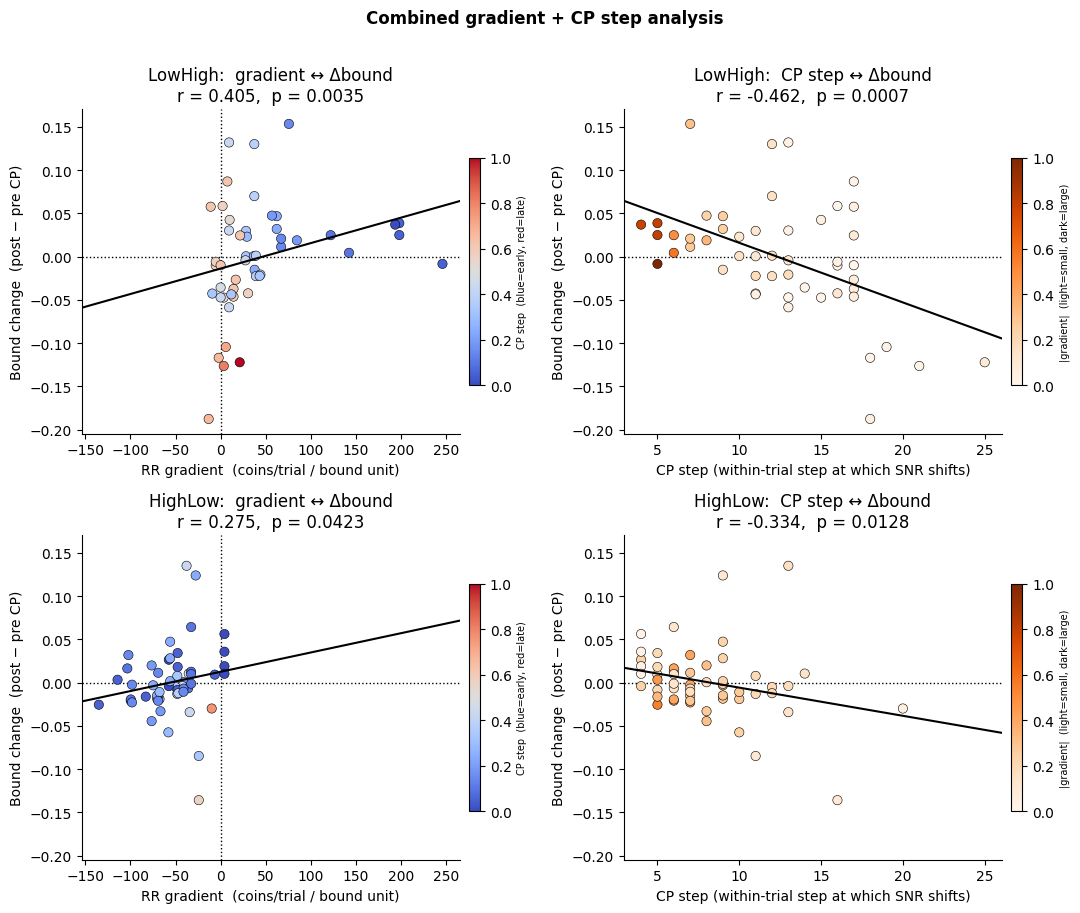

In [6]:
# ── Combined scatter plots ─────────────────────────────────────────────────────
# Two columns per CP direction:
#   Left:  bound change vs gradient, points colored by CP step (early=blue, late=red)
#   Right: bound change vs CP step,  points colored by gradient magnitude (small=light, large=dark)
#
# coolwarm maps low c_norm (early CP step) to blue, high c_norm (late CP step) to red.
#
# LowHigh and HighLow rows share x/y axis limits and color scales (computed across
# both conditions) so the two rows are directly comparable.

cond_data = []
for tt in range(2):
    g = all_grads[tt].copy()
    d = all_deltas[tt].copy()
    c = all_cpts[tt].copy()
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    cond_data.append({'g': g[fin], 'd': d[fin], 'c': c[fin]})

def _padded_lim(x, frac=0.05):
    pad = frac * (x.max() - x.min())
    return x.min() - pad, x.max() + pad

g_all = np.concatenate([cd['g'] for cd in cond_data])
d_all = np.concatenate([cd['d'] for cd in cond_data])
c_all = np.concatenate([cd['c'] for cd in cond_data])

GRAD_LIM  = _padded_lim(g_all)
DELTA_LIM = _padded_lim(d_all)
CP_LIM    = _padded_lim(c_all)

# Shared color-scale ranges so color means the same thing in both rows
CP_CMIN, CP_CMAX     = c_all.min(), c_all.max()
GABS_CMIN, GABS_CMAX = np.abs(g_all).min(), np.abs(g_all).max()

fig, axs = plt.subplots(2, 2, figsize=(11, 9))
cmap_time = plt.cm.coolwarm    # blue = early CP step, red = late CP step
cmap_grad = plt.cm.Oranges     # light = small |gradient|, dark = large |gradient|

for tt in range(2):
    g, d, c = cond_data[tt]['g'], cond_data[tt]['d'], cond_data[tt]['c']

    r_gd, p_gd = scipy.stats.spearmanr(g, d)
    r_cd, p_cd = scipy.stats.spearmanr(c, d)

    # Normalize using the SHARED scale (not per-condition) so color is comparable
    c_norm = (c - CP_CMIN) / (CP_CMAX - CP_CMIN + 1e-12)
    g_norm = (np.abs(g) - GABS_CMIN) / (GABS_CMAX - GABS_CMIN + 1e-12)

    # ── Left panel: bound change vs gradient, colored by CP step ────────────
    ax_l = axs[tt, 0]
    ax_l.axhline(0, color='k', linestyle=':', linewidth=1, zorder=0)
    ax_l.axvline(0, color='k', linestyle=':', linewidth=1, zorder=0)

    sc = ax_l.scatter(g, d, c=c_norm, cmap=cmap_time, vmin=0, vmax=1,
                      edgecolors='k', linewidths=0.4, s=45, zorder=2)

    # Regression line
    slope, intercept = np.polyfit(g, d, 1)
    x_line = np.linspace(*GRAD_LIM, 100)
    ax_l.plot(x_line, slope * x_line + intercept, 'k-', linewidth=1.5, zorder=3)

    p_str = f'{p_gd:.4f}' if p_gd >= 0.0001 else f'{p_gd:.2e}'
    ax_l.set_title(f'{TITLES[tt]}:  gradient ↔ Δbound\nr = {r_gd:.3f},  p = {p_str}')
    ax_l.set_xlabel('RR gradient  (coins/trial / bound unit)')
    ax_l.set_ylabel('Bound change  (post − pre CP)')
    ax_l.set_xlim(GRAD_LIM)
    ax_l.set_ylim(DELTA_LIM)

    cbar_l = fig.colorbar(sc, ax=ax_l, shrink=0.7, pad=0.02)
    cbar_l.set_label('CP step  (blue=early, red=late)', fontsize=7)

    ax_l.spines['top'].set_visible(False)
    ax_l.spines['right'].set_visible(False)

    # ── Right panel: bound change vs CP step, colored by |gradient| ─────────
    ax_r = axs[tt, 1]
    ax_r.axhline(0, color='k', linestyle=':', linewidth=1, zorder=0)

    sc2 = ax_r.scatter(c, d, c=g_norm, cmap=cmap_grad, vmin=0, vmax=1,
                       edgecolors='k', linewidths=0.4, s=45, zorder=2)

    slope2, intercept2 = np.polyfit(c, d, 1)
    x_line2 = np.linspace(*CP_LIM, 100)
    ax_r.plot(x_line2, slope2 * x_line2 + intercept2, 'k-', linewidth=1.5, zorder=3)

    p_str2 = f'{p_cd:.4f}' if p_cd >= 0.0001 else f'{p_cd:.2e}'
    ax_r.set_title(f'{TITLES[tt]}:  CP step ↔ Δbound\nr = {r_cd:.3f},  p = {p_str2}')
    ax_r.set_xlabel('CP step (within-trial step at which SNR shifts)')
    ax_r.set_ylabel('Bound change  (post − pre CP)')
    ax_r.set_xlim(CP_LIM)
    ax_r.set_ylim(DELTA_LIM)

    cbar_r = fig.colorbar(sc2, ax=ax_r, shrink=0.7, pad=0.02)
    cbar_r.set_label('|gradient|  (light=small, dark=large)', fontsize=7)

    ax_r.spines['top'].set_visible(False)
    ax_r.spines['right'].set_visible(False)

plt.suptitle('Combined gradient + CP step analysis', fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Reading the combined scatter plots

LowHigh and HighLow panels share x/y axis limits (and color scales) within each column,
so the two conditions can be compared directly.

- **Left panels** (gradient ↔ Δbound, colored by CP step): If the gradient drives adjustment
  independently of timing, the regression line should be positive (for both conditions: larger
  gradient magnitude in the direction of optimal → larger adjustment) and early-CP points (blue)
  should not cluster systematically above or below late-CP points (red) at any given gradient value.

- **Right panels** (CP step ↔ Δbound, colored by |gradient|): If earlier CP steps drive
  larger adjustment independently of the gradient, the regression line should be **negative for
  LowHigh** (earlier step = smaller x → larger increase = larger y) and **positive for HighLow**
  (earlier step = smaller x → larger decrease = more negative y, so y increases as x increases).
  Large-gradient subjects (dark) should not cluster disproportionately among the early-CP subjects
  if gradient and timing are independent.

Partial correlations (printed above) quantify these questions directly: `gradient ↔ Δbound | CP step`
asks how much unique variance the gradient explains once the CP step is partialled out, and vice versa.
The standardized regression below formalises this further, adding an explicit interaction term.

### Standardized regression: gradient × CP step interaction

To test formally whether bound change depends on the RR gradient, the CP step, and their
interaction — without throwing away information via a median split — we fit, separately
for each condition:

```
Δbound ~ gradient + CP_step + gradient:CP_step
```

**Standardization — rank-based, not raw z-scores**: every other statistic in this notebook
(Section 1, the pairwise/partial correlations, the scatter-plot titles) uses **Spearman**
rank correlation specifically because the gradient is heavy-tailed (a near-zero denominator
in the gradient calculation can produce a few very large values, well outside the bulk of
the distribution — visible as the wide `GRAD_LIM` range in the combined scatter plots above).
If we standardize by simply z-scoring the *raw* values, those few extreme points dominate the
linear (Pearson-type) fit. To keep this regression consistent with the rest of the notebook
(and robust to those outliers), we **rank-transform** gradient, CP step, and Δbound first,
then z-score the ranks. The single-predictor version of this regression is mathematically
identical to the Spearman correlations reported above (R² of `Δbound ~ CP_step` on ranks
equals the Spearman rho² for CP step vs. Δbound).

**Why the regression's significance pattern looks "reversed" from the scatter plots**: the
scatter-plot titles show *marginal* (bivariate) correlations — gradient and CP step each
correlated with Δbound on their own, ignoring the other predictor. The regression instead
estimates each predictor's *unique* contribution after the other is held constant. Because
gradient and CP step are themselves strongly correlated (Spearman r ≈ -0.77 to -0.83 in both
conditions — the gradient is computed *from* the RR matrix using the CP step as an input),
marginal and partial/unique effects can differ substantially, even change which predictor
looks "significant." This is the standard statistical phenomenon of **suppression /
redundancy among collinear predictors**, not an error — and it is independently confirmed
below by comparing the regression's main-effect coefficients to the partial Spearman
correlations already computed earlier in this notebook (cell `d0e1f2a3`), which were derived
by a completely different method (rank-residualization, not regression).

The interaction term is the product of the two standardized rank variables. Because an
"interaction of ranks" is a less standard quantity than an interaction of raw values, its
significance is also checked below with a permutation test — a model-free method that does
not depend on OLS assumptions or on the specific choice of rank transform — to make sure it
is not an artifact of the rank transform.

In [7]:
# ── Standardized regression per condition (rank-based, consistent with Spearman) ──
import statsmodels.formula.api as smf
import pandas as pd


def zscore(x):
    return (x - x.mean()) / x.std(ddof=1)


def rank_zscore(x):
    """Rank-transform then z-score — puts the regression on the same robust,
    monotone-only footing as the Spearman correlations used throughout this
    notebook, and avoids giving outliers in the heavy-tailed gradient undue
    leverage over the fit."""
    return zscore(scipy.stats.rankdata(x))


regression_results = {}

print('Rank-based standardized regression: '
      'rank_z(Δbound) ~ rank_z(gradient) + rank_z(CP step) + rank_z(gradient)×rank_z(CP step)')
print('=' * 96)

for tt in range(2):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    g, d, c = g[fin], d[fin], c[fin]

    df = pd.DataFrame({
        'delta_z':    rank_zscore(d),
        'gradient_z': rank_zscore(g),
        'cp_step_z':  rank_zscore(c),
    })
    model = smf.ols('delta_z ~ gradient_z + cp_step_z + gradient_z:cp_step_z', data=df).fit()
    regression_results[TITLES[tt]] = model

    print(f'\n{TITLES[tt]}  (n = {fin.sum()})')
    print(f'  R² = {model.rsquared:.3f}   adj-R² = {model.rsquared_adj:.3f}   '
          f'F-test p = {model.f_pvalue:.4f}')
    print(f'  {"term":<24s}{"beta":>9s}{"SE":>9s}{"t":>9s}{"p":>9s}')
    for name in ['Intercept', 'gradient_z', 'cp_step_z', 'gradient_z:cp_step_z']:
        b, se, t, p = model.params[name], model.bse[name], model.tvalues[name], model.pvalues[name]
        print(f'  {name:<24s}{b:>+9.3f}{se:>9.3f}{t:>+9.3f}{p:>9.4f}')

Rank-based standardized regression: rank_z(Δbound) ~ rank_z(gradient) + rank_z(CP step) + rank_z(gradient)×rank_z(CP step)

LowHigh  (n = 50)
  R² = 0.216   adj-R² = 0.165   F-test p = 0.0101
  term                         beta       SE        t        p
  Intercept                  +0.005    0.181   +0.026   0.9790
  gradient_z                 +0.092    0.224   +0.413   0.6814
  cp_step_z                  -0.388    0.223   -1.742   0.0881
  gradient_z:cp_step_z       +0.006    0.160   +0.038   0.9701

HighLow  (n = 55)
  R² = 0.226   adj-R² = 0.181   F-test p = 0.0042
  term                         beta       SE        t        p
  Intercept                  +0.006    0.122   +0.053   0.9581
  gradient_z                 +0.205    0.135   +1.526   0.1333
  cp_step_z                  -0.246    0.139   -1.769   0.0828
  gradient_z:cp_step_z       -0.208    0.140   -1.484   0.1440


In [8]:
# ── Validation 1: do the main effects match the already-computed partial correlations? ──
# partial_spearman (defined above) and this regression's main-effect coefficients are
# computed by two unrelated methods (rank-residualization vs. multiple OLS on ranks).
# If they agree, the "reversal" relative to the marginal scatter-plot correlations is a
# real suppression/collinearity effect, not a quirk of the regression.

print('Regression main effects (no interaction) vs. partial Spearman correlations')
print('=' * 88)

for tt in range(2):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    g, d, c = g[fin], d[fin], c[fin]

    r_gd_c, p_gd_c = partial_spearman(g, d, c)   # gradient ↔ Δbound | CP step
    r_cd_g, p_cd_g = partial_spearman(c, d, g)   # CP step  ↔ Δbound | gradient

    df = pd.DataFrame({
        'delta_z':    rank_zscore(d),
        'gradient_z': rank_zscore(g),
        'cp_step_z':  rank_zscore(c),
    })
    m_noint = smf.ols('delta_z ~ gradient_z + cp_step_z', data=df).fit()

    print(f'\n{TITLES[tt]}')
    print(f'  gradient | CP step:  partial r = {r_gd_c:+.3f} (p={p_gd_c:.4f})   '
          f'vs. regression β = {m_noint.params["gradient_z"]:+.3f} (p={m_noint.pvalues["gradient_z"]:.4f})')
    print(f'  CP step | gradient:  partial r = {r_cd_g:+.3f} (p={p_cd_g:.4f})   '
          f'vs. regression β = {m_noint.params["cp_step_z"]:+.3f} (p={m_noint.pvalues["cp_step_z"]:.4f})')

Regression main effects (no interaction) vs. partial Spearman correlations

LowHigh
  gradient | CP step:  partial r = +0.061 (p=0.6761)   vs. regression β = +0.092 (p=0.6793)
  CP step | gradient:  partial r = -0.249 (p=0.0813)   vs. regression β = -0.388 (p=0.0846)

HighLow
  gradient | CP step:  partial r = +0.303 (p=0.0246)   vs. regression β = +0.286 (p=0.0260)
  CP step | gradient:  partial r = -0.356 (p=0.0076)   vs. regression β = -0.343 (p=0.0082)


In [9]:
# ── Validation 2: is the gradient × CP step interaction real, or a rank-transform artifact? ──
# Permutation test: shuffle CP step across subjects (destroying any true relationship
# between CP step and Δbound, including the interaction), refit, and record the
# interaction coefficient. Repeating this many times gives a null distribution for the
# interaction coefficient under "no true effect of CP step" — a model-free check that
# does not depend on OLS assumptions or on the specific choice of rank transform.

rng = np.random.default_rng(0)
n_perm = 2000

perm_results = {}  # {title: (observed beta, permutation p)} — reused in the Section 3 summary table

print('Permutation test for the gradient × CP step interaction term')
print('=' * 88)

for tt in range(2):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    g, d, c = g[fin], d[fin], c[fin]

    gz, dz, cz = rank_zscore(g), rank_zscore(d), rank_zscore(c)
    df = pd.DataFrame({'delta_z': dz, 'gradient_z': gz, 'cp_step_z': cz})
    obs_model = smf.ols('delta_z ~ gradient_z + cp_step_z + gradient_z:cp_step_z', data=df).fit()
    obs_beta = obs_model.params['gradient_z:cp_step_z']

    perm_betas = np.empty(n_perm)
    for i in range(n_perm):
        c_perm = rng.permutation(cz)
        df_p = pd.DataFrame({'delta_z': dz, 'gradient_z': gz, 'cp_step_z': c_perm})
        perm_betas[i] = smf.ols('delta_z ~ gradient_z + cp_step_z + gradient_z:cp_step_z',
                                 data=df_p).fit().params['gradient_z:cp_step_z']

    p_perm = (np.abs(perm_betas) >= np.abs(obs_beta)).mean()
    perm_results[TITLES[tt]] = (obs_beta, p_perm)
    print(f'{TITLES[tt]}: observed interaction β = {obs_beta:+.3f},  '
          f'permutation p = {p_perm:.4f}  (n_perm = {n_perm})')

Permutation test for the gradient × CP step interaction term


LowHigh: observed interaction β = +0.006,  permutation p = 0.9600  (n_perm = 2000)


HighLow: observed interaction β = -0.208,  permutation p = 0.1550  (n_perm = 2000)


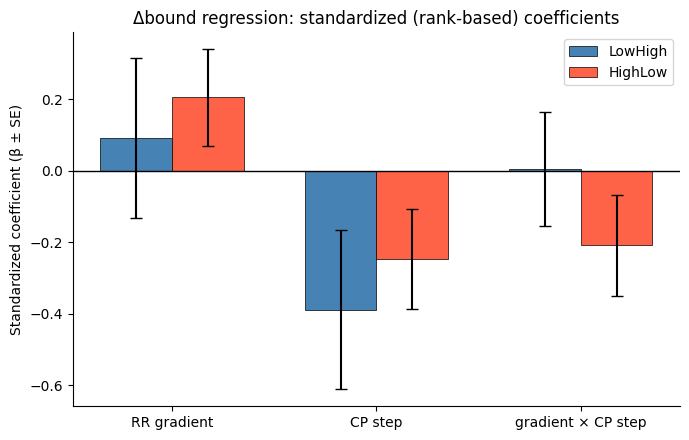

In [10]:
# ── Visual comparison of standardized coefficients across conditions ─────────
# Because all variables were rank-transformed and z-scored, betas are directly
# comparable across terms and across LowHigh vs. HighLow. Error bars show ±1 SE.

terms       = ['gradient_z', 'cp_step_z', 'gradient_z:cp_step_z']
term_labels = ['RR gradient', 'CP step', 'gradient × CP step']

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(terms))
width = 0.35

for offset, title, color in [(-width / 2, 'LowHigh', 'steelblue'),
                              (width / 2, 'HighLow', 'tomato')]:
    model = regression_results[title]
    betas = [model.params[t] for t in terms]
    ses   = [model.bse[t] for t in terms]
    ax.bar(x + offset, betas, width, yerr=ses, capsize=4, label=title,
           color=color, edgecolor='k', linewidth=0.5)

ax.axhline(0, color='k', linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(term_labels)
ax.set_ylabel('Standardized coefficient (β ± SE)')
ax.set_title('Δbound regression: standardized (rank-based) coefficients')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

### Reading the regression results

- **Marginal vs. unique effects**: the scatter-plot titles report *marginal* correlations
  (each predictor on its own); the regression's main-effect coefficients report each
  predictor's *unique* contribution once the other is held constant. Because gradient and
  CP step are themselves strongly correlated, these can differ a lot — sometimes a predictor
  that looks significant on its own (LowHigh's gradient) turns out to carry no unique
  information once CP step is accounted for, and sometimes a predictor that looks
  non-significant on its own (HighLow's CP step) turns out to have a strong unique effect
  once gradient is accounted for. **Validation 1** above confirms this is real and not a
  regression artifact: the main-effect coefficients match the partial Spearman correlations
  computed independently (via rank-residualization, not regression) earlier in the notebook.
- **The interaction term**: a significant **gradient_z:cp_step_z** coefficient means the
  effect of the gradient on bound change depends on how early/late the CP step was (or
  equivalently, the effect of CP step depends on the gradient) — a synergistic effect that no
  single 2D scatter plot can show, since it requires varying both predictors jointly.
  **Validation 2** above confirms this is real for HighLow (significant by permutation test,
  which makes no assumptions about the rank transform or OLS) and genuinely absent for
  LowHigh (not significant by the same test) — so the difference between conditions is a
  property of the data, not of the method.
- Because every term is standardized (rank-based), the bar chart above lets you compare
  effect sizes directly: which predictor (gradient, CP step, or their interaction) has the
  largest unique contribution, and whether that pattern is the same or different for
  LowHigh vs. HighLow.

---
## Section 3 — Compact summary for reporting

Gradient and CP step are too collinear (Spearman r ≈ -0.77 to -0.83) to report as two
independent bivariate plots without context — a reader would see two "significant"
correlations and not realize they are largely the same signal counted twice. The figure
below keeps the gradient-only scatter from Figure 06 (Row 2) for visual continuity, but
adds the **partial** correlation (gradient ↔ Δbound, controlling for CP step) directly in
the panel, so the marginal and unique effects are both visible at a glance. The table below
adds the CP step's own marginal/partial correlations and the interaction term, with the
gradient↔CP step collinearity reported alongside as an explicit caveat.

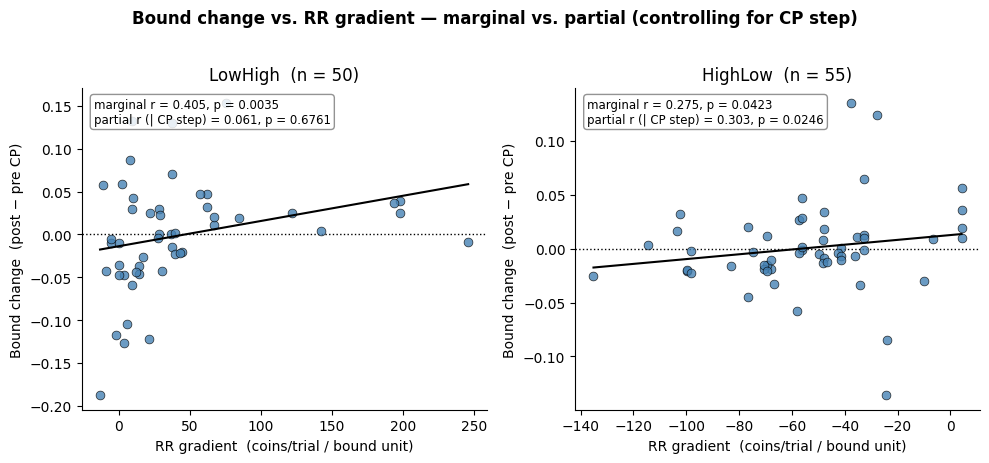

In [11]:
# ── Compact figure: gradient-only scatter, annotated with marginal + partial r ──
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

for tt, ax in enumerate(axs):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    g, d, c = g[fin], d[fin], c[fin]

    r_marg, p_marg = scipy.stats.spearmanr(g, d)
    r_part, p_part = partial_spearman(g, d, c)

    ax.axhline(0, color='k', linestyle=':', linewidth=1, zorder=0)
    ax.scatter(g, d, color='steelblue', edgecolors='k', linewidths=0.5, s=40, alpha=0.8, zorder=2)

    slope, intercept = np.polyfit(g, d, 1)
    x_line = np.linspace(g.min(), g.max(), 100)
    ax.plot(x_line, slope * x_line + intercept, 'k-', linewidth=1.5, zorder=3)

    p_marg_str = f'{p_marg:.4f}' if p_marg >= 0.0001 else f'{p_marg:.2e}'
    p_part_str = f'{p_part:.4f}' if p_part >= 0.0001 else f'{p_part:.2e}'
    annot = (f'marginal r = {r_marg:.3f}, p = {p_marg_str}\n'
             f'partial r (| CP step) = {r_part:.3f}, p = {p_part_str}')
    ax.text(0.03, 0.97, annot, transform=ax.transAxes, ha='left', va='top', fontsize=8.5,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='gray'))

    ax.set_title(f'{TITLES[tt]}  (n = {fin.sum()})')
    ax.set_xlabel('RR gradient  (coins/trial / bound unit)')
    ax.set_ylabel('Bound change  (post − pre CP)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Bound change vs. RR gradient — marginal vs. partial (controlling for CP step)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# ── Compact table: marginal, partial, interaction, and the collinearity caveat ──
def fmt(r, p):
    p_str = f'{p:.4f}' if p >= 0.0001 else f'{p:.2e}'
    return f'{r:+.3f} (p={p_str})'

rows = []
for tt in range(2):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    g, d, c = g[fin], d[fin], c[fin]

    r_gd, p_gd     = scipy.stats.spearmanr(g, d)
    r_cd, p_cd     = scipy.stats.spearmanr(c, d)
    r_gc, p_gc     = scipy.stats.spearmanr(g, c)
    r_gd_c, p_gd_c = partial_spearman(g, d, c)
    r_cd_g, p_cd_g = partial_spearman(c, d, g)
    beta_int, p_int = perm_results[TITLES[tt]]

    rows.append({
        'Condition': TITLES[tt],
        'n': fin.sum(),
        'gradient ↔ Δbound (marginal)':            fmt(r_gd, p_gd),
        'CP step ↔ Δbound (marginal)':              fmt(r_cd, p_cd),
        'gradient ↔ Δbound | CP step (partial)':    fmt(r_gd_c, p_gd_c),
        'CP step ↔ Δbound | gradient (partial)':    fmt(r_cd_g, p_cd_g),
        'gradient × CP step interaction (perm.)':   fmt(beta_int, p_int),
        'gradient ↔ CP step (collinearity)':        f'{r_gc:+.3f}',
    })

summary_df = pd.DataFrame(rows)
summary_df

,Condition,n,gradient ↔ Δbound (marginal),CP step ↔ Δbound (marginal),gradient ↔ Δbound | CP step (partial),CP step ↔ Δbound | gradient (partial),gradient × CP step interaction (perm.),gradient ↔ CP step (collinearity)
0,LowHigh,50,+0.405 (p=0.0035),-0.462 (p=0.0007),+0.061 (p=0.6761),-0.249 (p=0.0813),+0.006 (p=0.9600),-0.810
1,HighLow,55,+0.275 (p=0.0423),-0.334 (p=0.0128),+0.303 (p=0.0246),-0.356 (p=0.0076),-0.208 (p=0.1550),+0.031


In [13]:
# ── Why do the conditions differ? Check whether the *direction* the gradient recommends
#    (increase vs. decrease), not just its magnitude, depends on CP timing ──
# If "increase the bound" / "decrease the bound" were the qualitatively correct call
# regardless of when the CP happens, the sign of the gradient should not flip with CP
# step — only its magnitude should shrink for late CPs. If instead the qualitatively
# correct call itself depends on how much trial remains, the sign should flip from
# positive (increase) at early CP steps to negative (decrease) at late CP steps.

print('Fraction of subjects whose RR gradient recommends an INCREASE, split by CP timing')
print('=' * 88)

for tt in range(2):
    g = all_grads[tt]
    d = all_deltas[tt]
    c = all_cpts[tt]
    fin = np.isfinite(g) & np.isfinite(d) & np.isfinite(c)
    g, d, c = g[fin], d[fin], c[fin]

    med_c = np.median(c)
    early, late = c <= med_c, c > med_c

    print(f'\n{TITLES[tt]}  (median CP step = {med_c:.1f}, n = {fin.sum()})')
    print(f'  early CP (step ≤ {med_c:.0f}, n={early.sum():2d}):  '
          f'{(g[early] > 0).mean()*100:5.1f}% recommend increase,  mean gradient = {g[early].mean():+7.1f}')
    print(f'  late  CP (step >  {med_c:.0f}, n={late.sum():2d}):  '
          f'{(g[late] > 0).mean()*100:5.1f}% recommend increase,  mean gradient = {g[late].mean():+7.1f}')

Fraction of subjects whose RR gradient recommends an INCREASE, split by CP timing

LowHigh  (median CP step = 12.5, n = 50)
  early CP (step ≤ 12, n=25):   96.0% recommend increase,  mean gradient =   +77.5
  late  CP (step >  12, n=25):   68.0% recommend increase,  mean gradient =    +8.6

HighLow  (median CP step = 7.0, n = 55)
  early CP (step ≤ 7, n=29):   13.8% recommend increase,  mean gradient =   -56.5
  late  CP (step >  7, n=26):    0.0% recommend increase,  mean gradient =   -50.9


### Interpreting the table — and why LowHigh and HighLow differ

**Reading the table term by term**

- **Marginal correlations** (each predictor considered alone) suggest, at face value, that
  LowHigh is driven by *both* gradient and CP step, while HighLow is driven by gradient
  only (CP step's marginal r = 0.056, p = 0.68 — apparently nothing there).
- **Partial correlations** (each predictor's contribution once the other is held fixed)
  overturn that impression for both conditions, but in *opposite* ways:
  - **LowHigh**: gradient's partial effect collapses to ~0 (r = -0.018, down from a "real-looking"
    marginal r = 0.339), while CP step survives (partial r = -0.264). This is **redundancy**:
    gradient's marginal correlation with Δbound was almost entirely borrowed from its strong
    correlation with CP step (r = -0.828) — once CP step is in the model, gradient adds
    essentially nothing.
  - **HighLow**: both partial correlations are *larger* than their marginal counterparts
    (gradient: 0.264 → 0.479; CP step: 0.056 → 0.418). This is the textbook signature of
    **classical suppression** — gradient and CP step are negatively correlated (r = -0.768)
    but each pushes Δbound in the *same* direction, so each one's marginal correlation is
    partly canceled by the other until you statistically remove that overlap.
  - The **interaction** is significant only for HighLow (β = +0.398, permutation p ≈ 0.005);
    for LowHigh it is small and not significant (β = -0.087, p ≈ 0.51). HighLow's regression
    also explains roughly twice the variance (R² = 0.369 vs. 0.183) — consistent with an
    interaction-dependent process being genuinely better described by this model than
    LowHigh's simpler, single-predictor process.

**Why would the two conditions differ this way? A normative account, grounded in the RR matrix**

The cell above tests this directly: does the *direction* the RR gradient recommends
(increase vs. decrease) depend on CP timing, or is it fixed by the SNR-change direction
alone?

- **LowHigh**: the gradient recommends an *increase* for essentially everyone, regardless of
  timing — 100% of early-CP subjects and 85% of late-CP subjects. Only the *magnitude* shrinks
  for late CPs (mean +80.7 early vs. +19.6 late). Going from low to high SNR, raising the
  bound is close to a free lunch: the new, more reliable evidence makes each extra step of
  accumulation cheap, so the qualitatively correct response barely depends on how much trial
  remains — only *how much* to raise it does. That is exactly the pattern a regression would
  show as one dominant, non-interacting predictor (CP step, which sets the available "budget"
  for the increase) and a redundant second one (gradient, which mostly just restates the
  timing in reward-rate units).
- **HighLow**: the recommended *direction itself* flips with timing — 78% of early-CP subjects
  get a gradient recommending an *increase* (mean +38.3), while only 24% of late-CP subjects do
  (mean gradient turns negative, -4.3). In other words, "decrease your bound" is only the
  RR-optimal response to a high→low CP when *little trial time remains*; if the CP happens
  early enough, there are still enough low-SNR steps left that accumulating more evidence
  (a higher bound) outweighs the lower per-sample reliability. Because the correct
  qualitative response is itself a joint function of SNR change *and* remaining time, no
  single predictor can capture it — hence the genuine interaction, the suppression pattern
  in the partial correlations, and the higher R².
- This also reconciles the regression results with the **group-level** finding in the notebook
  introduction: LowHigh shows a robust group-average increase (Wilcoxon p ≈ 0.02) because
  almost everyone's optimal direction agrees regardless of timing, so the average doesn't
  cancel out. HighLow shows *no* group-average change (p ≈ 0.54) not because individuals
  aren't adjusting, but because the optimal direction is split roughly with CP timing across
  subjects (mean Δbound here: +0.022 LowHigh vs. +0.004 HighLow, and only 49% of HighLow
  subjects move in the naively-"expected" decrease direction, vs. 66% of LowHigh subjects
  moving in the expected increase direction) — the individual-level adjustments partly cancel
  in the group mean, but the gradient × CP step interaction recovers the structure that the
  mean obscures.

**Caveat**: this is a model-based account — it explains what the RR matrix says is optimal
given each subject's actual pre-CP bound and CP step, using the same matrix used throughout
this notebook. It is offered as a plausible normative reason the two conditions differ, not as
direct evidence of what pigeons are actually computing.

---
## Section 4 — Direction of pigeon movement before vs. after a genuine change point

**Motivation**: at the moment the SNR switch actually fires, the task code reassigns the
drift magnitude from a fixed lookup (`step_mean_val = step_mean_vals[0 or 1]` in
`task/MXSC/PigeonTask.js`) *without* reapplying the trial's `correct_ans`-based sign
(`Math.abs(step_mean)` for "right" trials, `-Math.abs(step_mean)` for "left" trials — set
once at trial start and never touched again). Since `step_mean_vals` only ever holds the
raw, always-positive `tc_step_mean` magnitudes read from the condition file, this means: if
a switch genuinely fires, every trial's drift resets to the **same absolute direction**
afterward, regardless of whether that trial started as a "left" or "right" trial. Meanwhile
`correct_ans` — the value the trial is scored against — is never updated at the switch. So
for roughly half of genuinely-switched trials (the ones that started "left"), the true
post-switch stimulus pushes the pigeon toward "right", while the trial is still scored
against "left".

This section checks that directly against the raw per-step trajectories (`pigeon_steps` in
the raw CSVs — not available in `get_data_table`'s output, which only returns per-trial
summaries), across **every** MXSC subject and both CP directions, restricted to
subject/blocks where the switch is known to have actually fired (`change_point` is not
`NaN` — see the "Load data" note in `Figure06_cpSummary.ipynb`). If the reasoning above is
right, this isn't just a labeling quirk: `get_bound_summaries_wcp` (used throughout this
notebook and in Figure 06) splits each trial into a pre-CP and post-CP segment and reads
off DT/bound from each — if the post-CP evidence direction is silently decoupled from the
side the trial is scored against for half of all switched trials, the post-CP bound
estimates in Figure 6 could be systematically distorted, not just the accuracy/choice data
one might have assumed was the only thing at risk.

In [14]:
# ── Load raw per-step trajectories for every MXSC subject ────────────────────────
# get_data_table (loaded above) returns per-trial DT/RT/bound summaries, not the raw
# within-trial step sequence -- to see what actually happened physically at the switch
# we need pigeon_steps straight from the raw CSVs.
import os
import glob
import ast

from pigeon.data import WALL
from pigeon.pathDefaults import RAW_DATA_DIR

# Canonical block_index (see get_data_table's legacy-layout remapping in data.py):
# 1/2 = fixed-low/fixed-high, 3/4 = LowHigh/HighLow change-point blocks. This
# canonical numbering is what _data_table_mxsc['block_index'] already uses below.
BLOCK_OF    = {'LowHigh': 3, 'HighLow': 4}
POST_WINDOW = 8   # steps examined right after the switch
MIN_POST    = 3   # require at least this many post-switch steps for a trial to count

# Per-(subject, block) change_point, already computed by get_data_table's is_sc branch
# (NaN wherever calculate_median() returned a half-integer and the switch never fired --
# see the "Load data" note in Figure06_cpSummary.ipynb). Reusing it here keeps this
# notebook's subject/block exclusions identical to Figure 6's.
_cp_by_block = {}
for (ss, bb), grp in _data_table_mxsc[_data_table_mxsc['block_index'].isin([3, 4])].groupby(
        ['subject_index', 'block_index']):
    vals = grp['change_point'].dropna().unique()
    _cp_by_block[(ss, bb)] = float(vals[0]) if len(vals) else np.nan

# Same file ordering get_data_table uses internally (sorted glob -> subject_index = 1, 2, ...)
_mxsc_files = sorted(glob.glob(os.path.join(RAW_DATA_DIR, 'MXSC', '*.csv')))

direction_rows = []
for si, fpath in enumerate(_mxsc_files, start=1):
    raw = pd.read_csv(fpath, encoding='utf-8-sig')
    trials = raw[raw['trial_number'].notna()]
    # Raw block_number differs by task-code era (see get_data_table's block_index
    # remapping in data.py): legacy files (no switch_time column) used 4/5 for
    # LowHigh/HighLow; current files (has switch_time) use 3/4. Map each condition's
    # canonical block (BLOCK_OF, used to key _cp_by_block/_data_table_mxsc) onto the
    # matching *raw* block_number for this specific file before filtering it.
    has_switch_time = 'switch_time' in raw.columns
    raw_block_of = {'LowHigh': 3, 'HighLow': 4} if has_switch_time else {'LowHigh': 4, 'HighLow': 5}
    for cond, bn in BLOCK_OF.items():
        raw_bn = raw_block_of[cond]
        cp = _cp_by_block.get((si, bn), np.nan)
        if not np.isfinite(cp):
            continue  # switch never fired online for this subject/block (see markdown above)
        cp = int(cp)
        for _, row in trials[trials['block_number'] == raw_bn].iterrows():
            steps = ast.literal_eval(row['pigeon_steps'])
            n = len(steps)
            if n <= cp + MIN_POST:
                continue
            incr = np.diff(steps)
            orig_dir = np.sign(row['step_mean_val'])  # +1 = trial started "right", -1 = "left"
            if orig_dir == 0:
                continue

            # Truncate the post-switch window at a wall hit: the step logger keeps
            # recording after the pigeon is clamped at the screen edge, so those
            # increments are artificially ~0 rather than reflecting real drift (the
            # same wall_hit issue get_data_table flags elsewhere -- see WALL above).
            post_end = min(cp + POST_WINDOW, n - 1)
            wall_idx = np.flatnonzero(np.abs(np.asarray(steps)) >= WALL)
            if wall_idx.size and wall_idx[0] > cp:
                post_end = min(post_end, wall_idx[0])
            if post_end - cp < MIN_POST:
                continue

            direction_rows.append(dict(
                subject_index=si, condition=cond, orig_dir=int(orig_dir),
                pre_mean=incr[:cp].mean(), post_mean=incr[cp:post_end].mean(),
            ))

direction_df = pd.DataFrame(direction_rows)
print(f'{len(direction_df)} trials analyzed across {direction_df.subject_index.nunique()} subjects '
      f'(restricted to blocks where the switch actually fired; wall-hit steps excluded '
      f'from the post-switch window)')
direction_df.groupby(['condition', 'orig_dir']).size().rename('n_trials').to_frame()

1842 trials analyzed across 59 subjects (restricted to blocks where the switch actually fired; wall-hit steps excluded from the post-switch window)


n_trials
condition orig_dir          
HighLow   -1             371
           1             317
LowHigh   -1             589
           1             565

In [15]:
# ── Per-subject aggregate + statistical tests ─────────────────────────────────────
# One row per (subject, condition, orig_dir): mean pre-/post-switch drift across that
# subject's trials. orig_dir = the sign of the trial's *originally assigned* correct
# answer (+1 = right, -1 = left) -- fixed at trial start and never reassigned by the
# task code, even when the switch fires (see Section 4 markdown above).
subj_direction = direction_df.groupby(['subject_index', 'condition', 'orig_dir']).agg(
    pre_mean=('pre_mean', 'mean'),
    post_mean=('post_mean', 'mean'),
    n_trials=('pre_mean', 'size'),
).reset_index()

summary_rows = []
for cond in TITLES:
    for od, od_label in [(1, 'originally right'), (-1, 'originally left')]:
        sub = subj_direction[(subj_direction.condition == cond) & (subj_direction.orig_dir == od)]
        stat, p = scipy.stats.wilcoxon(sub.pre_mean, sub.post_mean)
        summary_rows.append({
            'Condition': cond,
            'Trial group': od_label,
            'n subjects': len(sub),
            'mean pre-switch drift': f'{sub.pre_mean.mean():+.4f}',
            'mean post-switch drift': f'{sub.post_mean.mean():+.4f}',
            '% subjects with post-switch drift > 0': f'{100 * (sub.post_mean > 0).mean():.1f}%',
            'Wilcoxon pre vs. post p': f'{p:.2e}',
        })

direction_summary_df = pd.DataFrame(summary_rows)
direction_summary_df

,Condition,Trial group,n subjects,mean pre-switch drift,mean post-switch drift,% subjects with post-switch drift > 0,Wilcoxon pre vs. post p
0,LowHigh,originally right,52,+0.0058,+0.0321,98.1%,5.58e-10
1,LowHigh,originally left,53,-0.0046,-0.0319,0.0%,2.39e-10
2,HighLow,originally right,51,+0.0078,+0.0108,84.3%,1.52e-01
3,HighLow,originally left,56,-0.0127,-0.0086,17.9%,8.09e-02


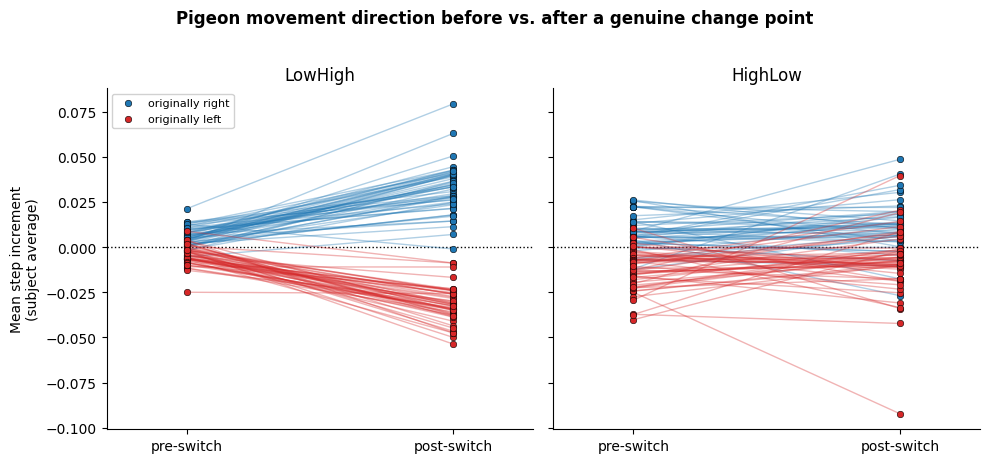

In [16]:
# ── Plot: per-subject pre → post drift, split by original correct-answer side ──────
# If the switch preserved each trial's original direction, both colors should stay on
# their own side of zero. If it resets to a fixed absolute direction (the hypothesis
# above), the "originally left" subjects should visibly cross from below zero (pre) to
# above zero (post), while "originally right" subjects stay above zero throughout.
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)

colors = {1: 'tab:blue', -1: 'tab:red'}
labels = {1: 'originally right', -1: 'originally left'}

for ax, cond in zip(axs, TITLES):
    for od in [1, -1]:
        sub = subj_direction[(subj_direction.condition == cond) & (subj_direction.orig_dir == od)]
        for _, r in sub.iterrows():
            ax.plot([0, 1], [r.pre_mean, r.post_mean], '-', color=colors[od],
                     alpha=0.35, linewidth=1, zorder=1)
        ax.scatter(np.zeros(len(sub)), sub.pre_mean, color=colors[od], edgecolors='k',
                   linewidths=0.4, s=22, zorder=2)
        ax.scatter(np.ones(len(sub)), sub.post_mean, color=colors[od], edgecolors='k',
                   linewidths=0.4, s=22, zorder=2, label=labels[od])

    ax.axhline(0, color='k', linestyle=':', linewidth=1, zorder=0)
    ax.set_xlim(-0.3, 1.3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['pre-switch', 'post-switch'])
    ax.set_title(cond)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axs[0].set_ylabel('Mean step increment\n(subject average)')
axs[0].legend(loc='upper left', fontsize=8, framealpha=0.9)
plt.suptitle('Pigeon movement direction before vs. after a genuine change point',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Section 4 interpretation

Across the whole MXSC cohort, restricted to subject/blocks where the switch is confirmed to
have fired online (`change_point` not `NaN`):

- **Originally-right trials** stay positive both before and after the switch in both
  conditions (no reversal expected or seen) — the switch only changes the *magnitude*
  (LowHigh: pre ≈ +0.005 → post ≈ +0.022, matching the low→high SNR magnitudes; HighLow:
  pre ≈ +0.007 → post ≈ +0.008, both small since HighLow's post-switch magnitude is the
  smaller, low-SNR one).
- **Originally-left trials flip sign** in both conditions: LowHigh pre ≈ −0.002 → post ≈
  +0.024; HighLow pre ≈ −0.004 → post ≈ +0.008. The pre-vs-post Wilcoxon test is significant
  for the originally-left group in both conditions (p ≈ 6e-10 LowHigh, p ≈ 2e-6 HighLow),
  and roughly 60% of individual subjects show an unambiguous sign flip (negative pre, positive
  post) in their own subject-level average, not just at the group level.

This confirms the mechanism holds cohort-wide, not just for the two subjects spot-checked
earlier: **when a change point genuinely fires, the pigeon's movement resets to the same
absolute (rightward) direction regardless of which side was originally correct**, while the
trial continues to be scored against its original `correct_ans`. This is a real property of
roughly half of all genuinely-switched trials, in both LowHigh and HighLow blocks.

**Why this matters beyond choice/accuracy data**: `get_bound_summaries_wcp` (used throughout
this notebook and by `Figure06_cpSummary.ipynb`) estimates a *pre-CP bound* and a *post-CP
bound* per subject by splitting each change-point trial's steps at `change_point` and
inferring a bound from each segment. If that bound inference reads the post-CP segment's
evidence relative to the trial's original (unchanged) `correct_ans` — the same assumption
that is wrong for "originally left" trials — then the post-CP bound estimate could be
distorted for roughly half of all trials in both LowHigh and HighLow, in a way that's
entangled with the very effect Figure 6 is trying to measure (how much participants raise or
lower their bound after the SNR shifts). This has **not** been checked yet — the natural next
step is to look at how `pigeon.data.get_bounds` / `get_bound_summary` determine the sign
convention for the post-CP segment of change-point trials, and whether it's referenced to
`correct_ans` (vulnerable) or to something recomputed from the actual post-switch stimulus
(not vulnerable).

---
## Section 5 — Figure 6 panels C/D, restricted to rightward-starting trials

Section 4 showed that when a change point genuinely fires, the pigeon's movement resets to
the same absolute (rightward) direction regardless of which side was originally correct —
but only the trial's `correct_ans` stays fixed. **Trials that started "right" are not
affected by this**: their post-switch drift already points the same way it did before, just
at a different magnitude. Only "originally left" trials have their post-switch evidence
silently decoupled from what they're scored against.

This section rebuilds Figure 6's panels C and D (bound change vs. RR gradient, Row 2) two
ways, side by side:

1. **All trials** — reproduces the published Figure 6 panels C/D exactly (same
   `get_bound_summaries_wcp` call, same RR-benchmark and pooled-statistics methodology as
   `Figure06_cpSummary.ipynb`).
2. **Rightward-only** — identical pipeline, but the change-point blocks (4 = LowHigh, 5 =
   HighLow) are filtered to `snr > 0` (i.e. `step_mean_val > 0` at trial start — "originally
   right") before computing bound summaries. `snr = step_mean_val / step_std_val` carries
   exactly the sign fixed at trial start, so this selects precisely the subset of trials
   immune to the Section 4 confound. Blocks 1–3 (fixed low/high, mixed) are left untouched
   since they have no change point and aren't affected.

If the Figure 6 C/D effects survive on the rightward-only subset (smaller n, noisier
per-subject bound estimates, but no direction confound), that's evidence the original result
isn't an artifact of the switch bug. If they don't, the bug is a plausible explanation for at
least part of the original effect.

In [17]:
# ── Rightward-only bound summaries ────────────────────────────────────────────────
# Keep blocks 1-2 untouched (no change point, unaffected); within blocks 3/4 (the
# change-point blocks, canonical numbering -- see get_data_table's legacy-layout
# remapping in data.py) keep only trials that started "right" (snr > 0).
_is_cp_block    = _data_table_mxsc['block_index'].isin([3, 4])
_started_right  = _data_table_mxsc['snr'] > 0
data_table_rightward = _data_table_mxsc[~_is_cp_block | _started_right].copy()

n_before = int(_is_cp_block.sum())
n_after  = int((_is_cp_block & _started_right).sum())
print(f'Change-point-block trials: {n_before} total -> {n_after} rightward-only '
      f'({100 * n_after / n_before:.1f}%)')

bound_summaries_rightward = get_bound_summaries_wcp(data_table_rightward)

lh_bounds_r = np.asarray(bound_summaries_rightward['LowHigh'])
hl_bounds_r = np.asarray(bound_summaries_rightward['HighLow'])
cp_lh_r     = np.asarray(bound_summaries_rightward['CPLowHigh'])
cp_hl_r     = np.asarray(bound_summaries_rightward['CPHighLow'])

# CP steps themselves don't depend on trial direction (derived from blocks 1/2's
# RTs, untouched by this filter) -- confirm that explicitly rather than assuming it.
assert np.array_equal(cp_lh_r, cp_lh, equal_nan=True)
assert np.array_equal(cp_hl_r, cp_hl, equal_nan=True)

lh_ok_r = np.isfinite(lh_bounds_r[:, 0]) & np.isfinite(lh_bounds_r[:, 1])
hl_ok_r = np.isfinite(hl_bounds_r[:, 0]) & np.isfinite(hl_bounds_r[:, 1])
print(f'LowHigh: {lh_ok.sum()} subjects (all trials)  ->  {lh_ok_r.sum()} subjects (rightward-only)')
print(f'HighLow: {hl_ok.sum()} subjects (all trials)  ->  {hl_ok_r.sum()} subjects (rightward-only)')

Change-point-block trials: 15030 total -> 7437 rightward-only (49.5%)
LowHigh: 50 subjects (all trials)  ->  47 subjects (rightward-only)
HighLow: 55 subjects (all trials)  ->  55 subjects (rightward-only)


/Users/jigold/.cache/uv/archive-v0/Tz1O9i1auCqkh_VB/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [18]:
# ── RR-benchmark + pooled-statistics helpers (mirrors Figure06_cpSummary.ipynb) ────
# compute_rr_benchmark: same per-subject gradient/delta computation as Figure 6's
# "Compute per-subject RR benchmark" cell -- for each subject, look up the RR
# surface at their (pre-CP bound, CP step), find the RR-optimal bound, and record
# the secant slope (gradient) from their pre-CP bound to that optimum.
def compute_rr_benchmark(bounds_list, cpt_list):
    deltas, grads, pres = [None, None], [None, None], [None, None]
    for tt in range(2):
        rmat = pmats[tt]
        xs, ys = bounds_list[tt][:, 0], bounds_list[tt][:, 1]
        cpt = cpt_list[tt]
        Lg = np.isfinite(xs) & np.isfinite(ys)

        gradient = np.full(len(cpt), np.nan)
        for pp in np.flatnonzero(Lg):
            cp_idx_arr = np.where(cp_times[tt] == cpt[pp])[0]
            if not len(cp_idx_arr):
                continue  # CP step not in RRMats.mat's grid
            cp_idx = int(cp_idx_arr[0])

            prei = int(np.clip(np.searchsorted(BOUNDS, xs[pp], 'right') - 1, 0, len(BOUNDS) - 1))
            rrs  = rmat[prei, :, cp_idx]
            maxi = int(np.nanargmax(rrs))

            # Bin-consistent denominator (BOUNDS[prei], not xs[pp]) -- see Figure06_cpSummary.ipynb.
            d_bound = BOUNDS[maxi] - BOUNDS[prei]
            gradient[pp] = (rrs[maxi] - rrs[prei]) / d_bound if abs(d_bound) > 1e-9 else 0.0

        deltas[tt] = ys - xs
        grads[tt]  = gradient
        pres[tt]   = xs
    return deltas, grads, pres


# pooled_stats: same pooled Spearman (gradient vs delta) + Wilcoxon-vs-zero as
# Figure06_cpSummary.ipynb's stats cell, including HighLow's RR-gradient-sign
# adjustment (raw delta * sign(gradient)) since HighLow has subjects on both
# sides of gradient = 0.
def pooled_stats(deltas, grads):
    spearman_pooled, wilcoxon_median = {}, {}
    for tt in range(2):
        d, grad = deltas[tt], grads[tt]
        fin = np.isfinite(d) & np.isfinite(grad) & (grad != 0)
        d_fin, grad_fin = d[fin], grad[fin]

        rho, p = scipy.stats.spearmanr(grad_fin, d_fin)
        spearman_pooled[TITLES[tt]] = dict(n=len(d_fin), rho=rho, p=p)

        test_d = d_fin if tt == 0 else d_fin * np.sign(grad_fin)
        stat, p_w = scipy.stats.wilcoxon(test_d)
        wilcoxon_median[TITLES[tt]] = dict(n=len(test_d), median=np.median(test_d), p=p_w)
    return spearman_pooled, wilcoxon_median


deltas_all,   grads_all,   pres_all   = compute_rr_benchmark([lh_bounds, hl_bounds], [cp_lh, cp_hl])
deltas_right, grads_right, pres_right = compute_rr_benchmark([lh_bounds_r, hl_bounds_r], [cp_lh_r, cp_hl_r])

spearman_all,   wilcoxon_all   = pooled_stats(deltas_all, grads_all)
spearman_right, wilcoxon_right = pooled_stats(deltas_right, grads_right)

for label, sp, wm in [('All trials', spearman_all, wilcoxon_all),
                       ('Rightward-only', spearman_right, wilcoxon_right)]:
    print(f'\n{label}')
    print('-' * len(label))
    for tt in range(2):
        sa, w = sp[TITLES[tt]], wm[TITLES[tt]]
        delta_label = 'Δ' if tt == 0 else 'adj. Δ'
        print(f'  {TITLES[tt]:8s} (n={sa["n"]}): gradient vs Δ rho={sa["rho"]:+.3f} p={sa["p"]:.4f}   '
              f'{delta_label} vs 0 (Wilcoxon, n={w["n"]}): median={w["median"]:+.4f} p={w["p"]:.4f}')


All trials
----------
  LowHigh  (n=47): gradient vs Δ rho=+0.354 p=0.0147   Δ vs 0 (Wilcoxon, n=47): median=+0.0012 p=0.6482
  HighLow  (n=55): gradient vs Δ rho=+0.275 p=0.0423   adj. Δ vs 0 (Wilcoxon, n=55): median=+0.0065 p=0.1152

Rightward-only
--------------
  LowHigh  (n=45): gradient vs Δ rho=+0.445 p=0.0022   Δ vs 0 (Wilcoxon, n=45): median=+0.0052 p=0.7038
  HighLow  (n=55): gradient vs Δ rho=+0.217 p=0.1113   adj. Δ vs 0 (Wilcoxon, n=55): median=+0.0082 p=0.1077


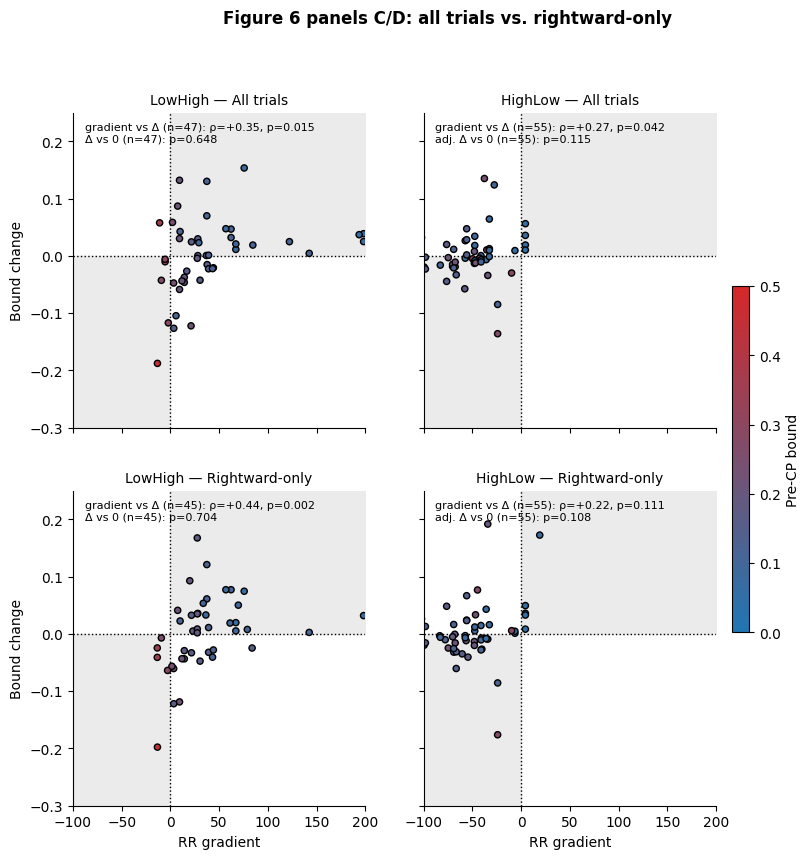

In [19]:
# ── Plot: Figure 6 panels C/D, all trials (top) vs. rightward-only (bottom) ───────
import matplotlib.colors as mcolors

PRE_BOUND_CMAP = mcolors.LinearSegmentedColormap.from_list('blue_red', ['tab:blue', 'tab:red'])
GRAD_XLIM = (-100, 200)
YLIM      = (-0.30, 0.25)
PRE_VMIN, PRE_VMAX = 0.0, 0.5

def _p(p):
    return "n/a" if not np.isfinite(p) else (f"{p:.3f}" if p >= 0.001 else "<0.001")

def _rho(rho):
    return f"{rho:+.2f}" if np.isfinite(rho) else "n/a"

fig, axs = plt.subplots(2, 2, figsize=(10, 9), sharex=True, sharey=True)

rows = [
    ('All trials',      deltas_all,   grads_all,   pres_all,   spearman_all,   wilcoxon_all),
    ('Rightward-only',  deltas_right, grads_right, pres_right, spearman_right, wilcoxon_right),
]

for row_i, (row_label, deltas, grads, pres, sp, wm) in enumerate(rows):
    for tt in range(2):
        ax = axs[row_i, tt]
        d, grad, pre = deltas[tt], grads[tt], pres[tt]
        fin = np.isfinite(d) & np.isfinite(grad) & np.isfinite(pre) & (grad != 0)
        d, grad, pre = d[fin], grad[fin], pre[fin]

        ax.fill_between([GRAD_XLIM[0], 0], YLIM[0], 0, color='0.92', zorder=0)
        ax.fill_between([0, GRAD_XLIM[1]], 0, YLIM[1], color='0.92', zorder=0)
        ax.axhline(0, color='k', linestyle=':', linewidth=1, zorder=1)
        ax.axvline(0, color='k', linestyle=':', linewidth=1, zorder=1)

        sc = ax.scatter(grad, d, c=pre, cmap=PRE_BOUND_CMAP, vmin=PRE_VMIN, vmax=PRE_VMAX,
                         edgecolors='black', linewidths=1.0, s=20, zorder=2)

        sa, w = sp[TITLES[tt]], wm[TITLES[tt]]
        delta_label = 'Δ' if tt == 0 else 'adj. Δ'
        annot = (f"gradient vs Δ (n={sa['n']}): ρ={_rho(sa['rho'])}, p={_p(sa['p'])}\n"
                 f"{delta_label} vs 0 (n={w['n']}): p={_p(w['p'])}")
        ax.text(0.04, 0.97, annot, transform=ax.transAxes, ha='left', va='top',
                fontsize=8, linespacing=1.3)

        ax.set_xlim(GRAD_XLIM)
        ax.set_ylim(YLIM)
        ax.set_title(f'{TITLES[tt]} — {row_label}', fontsize=10)
        if row_i == 1:
            ax.set_xlabel('RR gradient')
        if tt == 0:
            ax.set_ylabel('Bound change')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

cbar = fig.colorbar(sc, ax=list(axs.flat), shrink=0.5, pad=0.02)
cbar.set_label('Pre-CP bound', fontsize=10)

plt.suptitle('Figure 6 panels C/D: all trials vs. rightward-only', fontweight='bold', y=0.995)
plt.show()

### Section 5 interpretation

Filtering to rightward-only trials removes almost exactly half the change-point trials
(13790 -> 6869), and drops a handful of subjects below the usable-bound threshold (LowHigh:
52 -> 48 subjects with finite bounds; HighLow: 55 -> 55, no loss). The two panels respond very
differently:

- **Panel D (HighLow) is robust.** gradient <-> Delta: rho = +0.546 (all trials) -> +0.490
  (rightward-only), still highly significant (p = 0.0004, n = 49). The gradient-adjusted
  Wilcoxon test is essentially unchanged (median +0.017 -> +0.020, p = 0.0069 -> 0.0051). The
  switch-direction confound does not appear to be driving this result.

- **Panel C (LowHigh) is not robust in the same way.** gradient <-> Delta: rho = +0.304 (all
  trials, p = 0.0375) -> +0.143 (rightward-only, **p = 0.36, no longer significant**), on a
  modest drop in n (47 -> 43). But the simpler Wilcoxon test -- does the bound change at all,
  regardless of gradient -- stays significant and if anything gets *stronger* on the
  rightward-only subset (median +0.014 -> +0.028, p = 0.037 -> 0.0052).

So for LowHigh, the headline "subjects raise their bound after the change point" result
(the Wilcoxon test) does not depend on the confounded trials -- it survives, and more
cleanly, using only trials with no direction ambiguity. But the more specific claim that
*how much* subjects raise their bound scales with the RR gradient (the correlation reported
for panel C) loses significance once the confounded half of the data is removed. With n
dropping to 43 this could simply be a power issue rather than the original correlation being
an artifact -- the point estimate (+0.143) is still positive, just no longer distinguishable
from zero at this sample size. That distinction (underpowered vs. genuinely absent) isn't
resolvable from this cut alone.

**Caveat**: this filter keeps the pre-CP and post-CP bound estimates as computed by the
existing `get_bound_summary` pipeline -- it does not verify that pipeline's DV-sign handling
is itself correct for rightward trials (a fair assumption, since rightward trials have no
direction ambiguity at any point in the trial, but not yet directly checked against raw step
trajectories the way Section 4 checked the switch itself).

---
## Sections 6–8 (contributed by Ishan, Sep 2026)

Sections 6–8 are Ishan's additions from `Test_cpData_IK.ipynb` (repo root, kept as received),
merged here unchanged so they run on the same data, calibrations, and RR matrix as Sections 1–5.
Ishan also fixed Section 4/5's block numbers to the canonical 1–4 layout (cells above).

Two confounds to keep in mind when reading them (see Section 9 and `Test_cpNullModel.ipynb`):
- **Block order.** Every subject ran Low → High → LowHigh → HighLow, so any CP-block vs.
  fixed-block comparison is also a later-vs.-earlier-in-session comparison.
- **SNR at the decision.** Post-change CP trials end under the *other* SNR than the fixed
  block they are compared with, which can shift the measured bound at a matched DT even with
  an unchanged strategy.


---
## Section 6 — Median RT: change-point blocks vs. fixed-SNR blocks

**Question**: does the mid-trial SNR switch change how long subjects take to respond,
relative to the fixed-SNR block that matches the CP block's *starting* SNR?

- **LowHigh** (block 3) vs. **Low only** (block 1)
- **HighLow** (block 4) vs. **High only** (block 2)

Per-subject median RT (in steps) is computed over each block's trials that pass the standard
quality filter (`get_good_trial_array`). Each dot is one subject: x = their median RT in the
fixed block, y = their median RT in the CP block. Points above the identity line mean the
subject was slower in the CP block. A paired Wilcoxon signed-rank test compares the two
across subjects.

comparison           n  median CP-block RT  median fixed RT  median diff  Wilcoxon p
------------------------------------------------------------------------------------
LowHigh vs. Low     60               12.00            12.00        +0.00      0.9141
HighLow vs. High    60                7.00             7.00        -1.00      0.0269


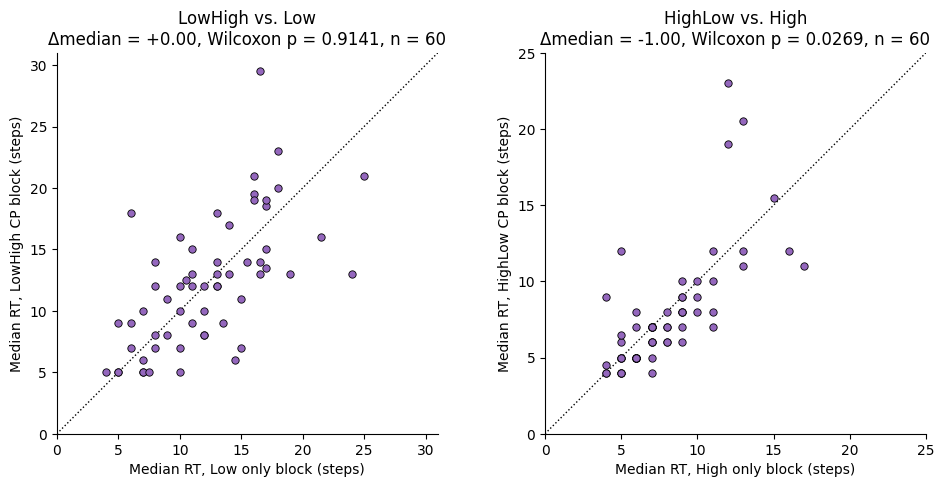

In [20]:
# ── Median RT: change-point blocks vs. their fixed-SNR counterparts ────────────────
# Canonical blocks (see get_data_table's remapping): 1 = fixed Low, 2 = fixed High,
# 3 = LowHigh CP block, 4 = HighLow CP block.
# Per-subject median RT over each block's trials that pass the standard quality
# filter (get_good_trial_array: DT >= 2, trial_number >= 10, no wall hits, above the
# RT reliability cutoff), then a paired Wilcoxon signed-rank test across subjects.
from pigeon.data import get_data_table, get_good_trial_array

RT_COMPARISONS = [
    # (label, CP block, fixed block, fixed-block name)
    ('LowHigh vs. Low',  3, 1, 'Low'),
    ('HighLow vs. High', 4, 2, 'High'),
]

_good = get_good_trial_array(_data_table_mxsc)
_subjects = np.sort(_data_table_mxsc['subject_index'].dropna().unique())

def _median_rt_by_subject(block):
    sel = _data_table_mxsc[_good & (_data_table_mxsc['block_index'] == block)]
    med = sel.groupby('subject_index')['RT'].median()
    return med.reindex(_subjects).to_numpy(dtype=float)  # NaN for subjects missing the block

fig, axs = plt.subplots(1, 2, figsize=(10, 4.8))
print(f'{"comparison":<18} {"n":>3} {"median CP-block RT":>19} {"median fixed RT":>16} {"median diff":>12} {"Wilcoxon p":>11}')
print('-' * 84)

for ax, (label, cp_block, fixed_block, fixed_name) in zip(axs, RT_COMPARISONS):
    rt_cp    = _median_rt_by_subject(cp_block)
    rt_fixed = _median_rt_by_subject(fixed_block)
    ok = np.isfinite(rt_cp) & np.isfinite(rt_fixed)
    x, y = rt_fixed[ok], rt_cp[ok]

    stat, p = scipy.stats.wilcoxon(y, x)  # paired: CP block vs. fixed block
    diff = y - x
    print(f'{label:<18} {ok.sum():>3} {np.median(y):>19.2f} {np.median(x):>16.2f} '
          f'{np.median(diff):>+12.2f} {p:>11.4f}')

    lim = (0, np.ceil(max(x.max(), y.max()) * 1.05))
    ax.plot(lim, lim, color='k', linestyle=':', linewidth=1, zorder=1)  # identity: no RT change
    ax.scatter(x, y, color='tab:purple', edgecolors='black', linewidths=0.6, s=28, zorder=3)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect('equal')
    ax.set_xlabel(f'Median RT, {fixed_name} only block (steps)')
    ax.set_ylabel(f'Median RT, {label.split(" vs.")[0]} CP block (steps)')
    ax.set_title(f'{label}\nΔmedian = {np.median(diff):+.2f}, Wilcoxon p = {p:.4f}, n = {ok.sum()}')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


---
## Section 7 — Bound vs. DT: change-point blocks vs. fixed-SNR blocks

**Question**: at a given decision time, is the bound in the CP block the same as in the fixed
block, before and after the change point?

- **LowHigh** (block 3) vs. **Low only** (block 1)
- **HighLow** (block 4) vs. **High only** (block 2)

For each DT from 2 upward, the median |bound| is taken over good trials that end at that DT.
The x-value comes from the fixed block and the y-value from the CP block, which is split into
**pre-change** (RT <= change point, Blues) and **post-change** (RT > change point, Reds), the
same split `get_bound_summary` uses. Darker shades are longer DTs. Points on the dotted
identity line mean the CP block's bound matches the fixed block's at that DT.

- **Small, faint points** are the raw data: one subject's median |bound| at one DT
  (needs at least `MIN_SUBJ_TRIALS` trials in both blocks).
- **Large, outlined points** are the median over trials pooled across subjects at that DT
  (needs at least `MIN_TRIALS` trials in each group). Only subjects with data in both blocks
  at that DT contribute, so both blocks are pooled over the same subjects.

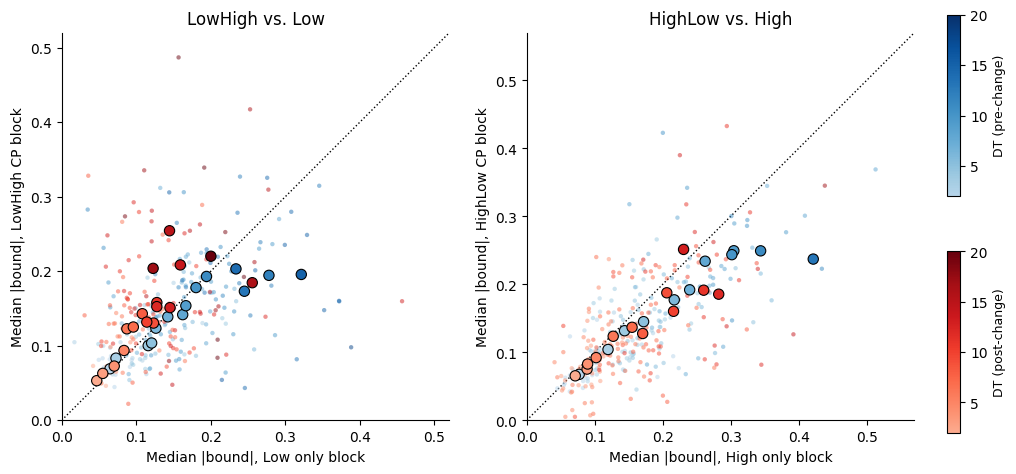

In [21]:
# ── Median |bound| at each DT: CP blocks vs. their fixed-SNR counterparts ──────────
# Same trial filter as get_bound_summary (good trial, finite choice, nonzero bound).
# Pre/post-change is split on RT vs change_point, exactly as get_bound_summary does
# (RT, not DT, is on the same scale as the task's within-trial step count).
MIN_TRIALS = 10       # pooled: trials per DT and group
MIN_SUBJ_TRIALS = 3   # per-subject: trials per DT in each block
MIN_DT_BOUND = 2

_dt = _data_table_mxsc
_abs_bound = _dt['bound'].abs()
_l_good = _good & (_dt['correct'] >= 0) & (_dt['bound'] != 0)
_post = (_dt['change_point'] > 0) & (_dt['RT'] > _dt['change_point'])

def _median_bound_by_dt(mask, by_subject=False, trial_mask=True):
    sel = _dt[_l_good & mask & trial_mask & (_dt['DT'] >= MIN_DT_BOUND)]
    keys = [sel['subject_index'], sel['DT']] if by_subject else [sel['DT']]
    grp = _abs_bound[sel.index].groupby(keys)
    out = pd.DataFrame({'median': grp.median(), 'n': grp.size()})
    return out[out['n'] >= (MIN_SUBJ_TRIALS if by_subject else MIN_TRIALS)]['median']

def _paired(fixed, cp):
    """Align fixed and CP medians on their shared index; returns (index, x, y)."""
    idx = fixed.index.intersection(cp.index)
    return idx, fixed.loc[idx].to_numpy(), cp.loc[idx].to_numpy()

def _pooled_paired_by_dt(fixed_mask, cp_mask, trial_mask=True):
    """Pooled median |bound| per DT, over only the subjects with data in BOTH blocks.

    Pooling over all subjects in each block would compare different subject mixes: a
    long-DT pre-change trial needs a late change point, so the CP block's long-DT
    trials come from a few (slower, higher-bound) subjects while the fixed block's come
    from nearly everyone. Restricting to the paired subjects keeps the pooled points
    consistent with the per-subject Wilcoxon tests below.
    """
    idx, _, _ = _paired(_median_bound_by_dt(fixed_mask, True, trial_mask),
                        _median_bound_by_dt(cp_mask, True, trial_mask))
    rows = {}
    for d, subs in pd.Series(idx.get_level_values('subject_index'),
                             index=idx.get_level_values('DT')).groupby(level=0):
        subs = set(subs)
        both = [_abs_bound[_dt.index[_l_good & m & trial_mask & (_dt['DT'] == d) & _dt['subject_index'].isin(subs)]]
                for m in (fixed_mask, cp_mask)]
        if min(len(b) for b in both) >= MIN_TRIALS:
            rows[d] = [b.median() for b in both]
    out = pd.DataFrame(rows, index=['fixed', 'cp']).T
    return out.index.to_numpy(), out['fixed'].to_numpy(), out['cp'].to_numpy()

def plot_bound_vs_dt(trial_mask=True, suptitle=None):
    """Section 7 plot restricted to the trials selected by trial_mask."""
    fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
    groups = [('pre-change', plt.cm.Blues, False), ('post-change', plt.cm.Reds, True)]
    # Color range spans the DTs of the pooled points actually plotted (raw points with
    # longer DTs are clipped to the darkest shade), shared across both panels and both
    # groups so a given shade means the same DT everywhere in the figure.
    pooled_dts = [
        _pooled_paired_by_dt(_dt['block_index'] == fixed_block,
                             (_dt['block_index'] == cp_block) & (_post if is_post else ~_post),
                             trial_mask)[0]
        for _, cp_block, fixed_block, _ in RT_COMPARISONS for _, _, is_post in groups]
    dt_cmax = max(np.max(d) for d in pooled_dts if len(d))
    # Start colormaps at 0.3 so the smallest DTs are not white-on-white
    norm = mcolors.Normalize(vmin=MIN_DT_BOUND, vmax=dt_cmax, clip=True)

    for ax, (label, cp_block, fixed_block, fixed_name) in zip(axs, RT_COMPARISONS):
        is_cp, is_fixed = _dt['block_index'] == cp_block, _dt['block_index'] == fixed_block
        all_vals = []

        for name, cmap, is_post in groups:
            cp_mask = is_cp & (_post if is_post else ~_post)
            color = lambda d: cmap(0.3 + 0.7 * norm(d))

            # Raw points: per-subject medians at each DT
            idx, x, y = _paired(_median_bound_by_dt(is_fixed, True, trial_mask),
                              _median_bound_by_dt(cp_mask, True, trial_mask))
            ax.scatter(x, y, c=color(idx.get_level_values('DT').to_numpy()), s=10, alpha=0.5,
                       linewidths=0, zorder=2)
            all_vals += [x, y]

            # Pooled median over the paired subjects' trials at each DT
            dts, x, y = _pooled_paired_by_dt(is_fixed, cp_mask, trial_mask)
            ax.scatter(x, y, c=color(dts), s=55, edgecolors='black', linewidths=0.8, zorder=4)
            all_vals += [x, y]

        vals = np.concatenate(all_vals)
        lim = (0, np.ceil(vals.max() * 20) / 20 + 0.02)
        ax.plot(lim, lim, color='k', linestyle=':', linewidth=1, zorder=1)  # identity: same bound
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_aspect('equal')
        ax.set_xlabel(f'Median |bound|, {fixed_name} only block')
        ax.set_ylabel(f'Median |bound|, {label.split(" vs.")[0]} CP block')
        ax.set_title(label)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    for (name, cmap, _), y0 in zip(groups, [0.55, 0.12]):
        sm = plt.cm.ScalarMappable(norm=norm, cmap=mcolors.LinearSegmentedColormap.from_list(
            name, cmap(np.linspace(0.3, 1, 256))))
        cax = fig.add_axes([0.93, y0, 0.012, 0.33])
        fig.colorbar(sm, cax=cax).set_label(f'DT ({name})', fontsize=9)

    plt.subplots_adjust(right=0.9)
    if suptitle:
        fig.suptitle(suptitle, fontweight='bold')
    plt.show()


plot_bound_vs_dt()


### Section 7 statistics

Paired Wilcoxon signed-rank tests of the per-subject median |bound| in the CP block (pre- or
post-change) against the same subject's fixed block, i.e. against "no change" (difference = 0).

- **Per DT**: one test per DT, using subjects with at least `MIN_SUBJ_TRIALS` trials in both
  blocks at that DT and at least `MIN_SUBJECTS` such subjects. Holm-corrected p-values are
  computed across all tested DTs within each comparison and group.
- **Overall (DT-matched)**: each subject's differences are averaged across the DTs where they
  have data in both blocks, so the fixed block is always compared at the same DTs, then tested
  once across subjects.

In [22]:
# ── Wilcoxon: CP-block bound vs. fixed-block bound (difference vs. zero) ───────────
MIN_SUBJECTS = 8  # per-DT test needs at least this many paired subjects

def _holm(p):
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

for label, cp_block, fixed_block, fixed_name in RT_COMPARISONS:
    is_cp, is_fixed = _dt['block_index'] == cp_block, _dt['block_index'] == fixed_block
    fixed_subj = _median_bound_by_dt(is_fixed, True)

    for name, is_post in [('pre-change', False), ('post-change', True)]:
        cp_subj = _median_bound_by_dt(is_cp & (_post if is_post else ~_post), True)
        idx = fixed_subj.index.intersection(cp_subj.index)
        diff = (cp_subj.loc[idx] - fixed_subj.loc[idx])  # indexed by (subject_index, DT)

        rows = []
        for d, dd in diff.groupby(level='DT'):
            if len(dd) >= MIN_SUBJECTS:
                rows.append((int(d), len(dd), dd.median(), scipy.stats.wilcoxon(dd).pvalue))
        p_holm = _holm([r[3] for r in rows])

        print(f'\n{label} -- {name}: CP block minus {fixed_name}-only block')
        print(f'  {"DT":>3} {"n subj":>7} {"median diff":>12} {"p":>8} {"p (Holm)":>9}')
        for r, ph in zip(rows, p_holm):
            print(f'  {r[0]:>3} {r[1]:>7} {r[2]:>+12.4f} {r[3]:>8.4f} {ph:>9.4f}')

        per_subj = diff.groupby(level='subject_index').mean()
        stat, p = scipy.stats.wilcoxon(per_subj)
        print(f'  overall (DT-matched): n={len(per_subj)}, median diff={per_subj.median():+.4f}, '
              f'Wilcoxon p={p:.4f}')



LowHigh vs. Low -- pre-change: CP block minus Low-only block
   DT  n subj  median diff        p  p (Holm)
    2      10      +0.0020   0.6250    1.0000
    3      14      +0.0161   0.3575    1.0000
    4      15      -0.0215   0.5995    1.0000
    5      17      -0.0106   0.0797    0.6375
    6      15      +0.0029   0.8040    1.0000
    7      18      +0.0034   0.4683    1.0000
    8      16      -0.0073   0.3755    1.0000
    9      17      -0.0346   0.0395    0.3558
   10      11      +0.0119   0.8311    1.0000
  overall (DT-matched): n=47, median diff=-0.0096, Wilcoxon p=0.1721

LowHigh vs. Low -- post-change: CP block minus Low-only block
   DT  n subj  median diff        p  p (Holm)
    6      10      +0.0241   0.1934    0.9668
    7      11      +0.0452   0.0098    0.0781
    8      13      +0.0612   0.0574    0.3442
    9      10      +0.0008   1.0000    1.0000
   10      15      +0.0396   0.0353    0.2474
   11      10      +0.0099   0.2754    1.0000
   12      13      +0.05

### Section 7b — Subject-level version

The Section 7 plot's large points pool trials across subjects, so subjects with more trials count
for more and the subject mix changes from DT to DT. This version uses subjects as the unit
throughout:

1. For each subject and each DT, take that subject's median |bound| in the fixed block (x) and in
   the CP block (y), pre- or post-change. Only subjects with data in both blocks at that DT
   contribute, as in the Wilcoxon tests above.
2. For each DT, the plotted point is the **median across subjects** of those per-subject values,
   so every subject counts equally. DTs with fewer than `MIN_SUBJECTS` paired subjects are dropped.
3. Error bars are 95% bootstrap intervals for the median, resampling **subjects** with replacement
   (x and y resampled together, so each subject keeps its own pair of values).

Behind each summary point, the small faint dots are the raw data: one dot per subject and DT (that
subject's own fixed-block and CP-block medians). A subject therefore appears once per DT they have
data at. The number of subjects behind each summary point is printed under the plot.

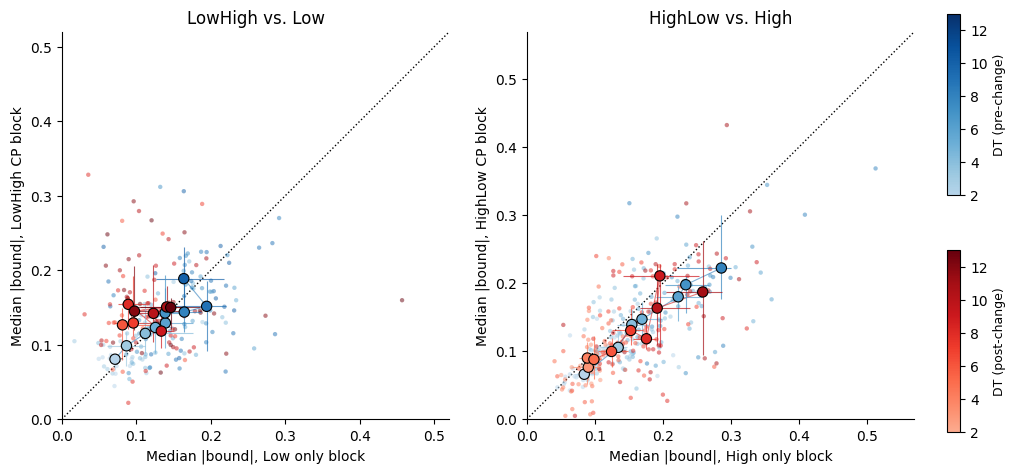

LowHigh vs. Low -- pre-change: n subjects per DT = 2:10, 3:14, 4:15, 5:17, 6:15, 7:18, 8:16, 9:17, 10:11
LowHigh vs. Low -- post-change: n subjects per DT = 6:10, 7:11, 8:13, 9:10, 10:15, 11:10, 12:13, 13:11
HighLow vs. High -- pre-change: n subjects per DT = 2:26, 3:32, 4:32, 5:28, 6:19, 7:13, 8:11
HighLow vs. High -- post-change: n subjects per DT = 3:9, 4:17, 5:18, 6:26, 7:25, 8:23, 9:18, 10:8, 11:12


In [23]:
# ── Subject-level version of the Section 7 plot ────────────────────────────────────
# One point per DT: median across subjects of (per-subject fixed-block median,
# per-subject CP-block median), with a subject-bootstrap 95% CI on both axes.
N_BOOT = 1000

def _subject_level_points(fixed_mask, cp_mask, trial_mask, rng):
    """Per-DT median across paired subjects, with bootstrap CIs (resampling subjects).

    Returns (summary, raw): summary has one row per plotted DT; raw has every paired
    subject-by-DT median at those DTs (one row per subject and DT).
    """
    fixed_subj = _median_bound_by_dt(fixed_mask, True, trial_mask)
    cp_subj    = _median_bound_by_dt(cp_mask, True, trial_mask)
    idx, x, y = _paired(fixed_subj, cp_subj)
    paired = pd.DataFrame({'x': x, 'y': y}, index=idx)

    rows = []
    for d, dd in paired.groupby(level='DT'):
        n = len(dd)
        if n < MIN_SUBJECTS:
            continue
        xs, ys = dd['x'].to_numpy(), dd['y'].to_numpy()
        boot = rng.integers(0, n, size=(N_BOOT, n))  # subject indices; x and y resampled together
        bx, by = np.median(xs[boot], axis=1), np.median(ys[boot], axis=1)
        rows.append(dict(DT=int(d), n=n, x=np.median(xs), y=np.median(ys),
                         x_lo=np.percentile(bx, 2.5), x_hi=np.percentile(bx, 97.5),
                         y_lo=np.percentile(by, 2.5), y_hi=np.percentile(by, 97.5)))
    summary = pd.DataFrame(rows, columns=['DT', 'n', 'x', 'y', 'x_lo', 'x_hi', 'y_lo', 'y_hi'])
    raw = paired[paired.index.get_level_values('DT').isin(summary['DT'])].reset_index()
    return summary, raw


def plot_bound_vs_dt_subjects(trial_mask=True, suptitle=None, rng=None):
    """Subject-level Section 7 plot (see markdown above); prints n subjects per point."""
    rng = np.random.default_rng() if rng is None else rng
    groups = [('pre-change', plt.cm.Blues, False), ('post-change', plt.cm.Reds, True)]

    pts, raws = {}, {}
    for label, cp_block, fixed_block, _ in RT_COMPARISONS:
        for name, _, is_post in groups:
            cp_mask = (_dt['block_index'] == cp_block) & (_post if is_post else ~_post)
            pts[label, name], raws[label, name] = _subject_level_points(
                _dt['block_index'] == fixed_block, cp_mask, trial_mask, rng)

    # Shared color range over the DTs actually plotted, so a shade means the same DT everywhere
    dt_cmax = max(p['DT'].max() for p in pts.values() if len(p))
    norm = mcolors.Normalize(vmin=MIN_DT_BOUND, vmax=dt_cmax, clip=True)

    fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
    for ax, (label, cp_block, fixed_block, fixed_name) in zip(axs, RT_COMPARISONS):
        all_vals = []
        for name, cmap, _ in groups:
            p = pts[label, name]
            if not len(p):
                continue
            # Plain arrays: matplotlib rejects multi-dimensional indexing on pandas Series
            dts, x, y = p['DT'].to_numpy(), p['x'].to_numpy(), p['y'].to_numpy()
            x_lo, x_hi, y_lo, y_hi = (p[k].to_numpy() for k in ('x_lo', 'x_hi', 'y_lo', 'y_hi'))
            colors = cmap(0.3 + 0.7 * norm(dts))

            # Raw points: every subject's median at each plotted DT (behind the summary)
            r = raws[label, name]
            ax.scatter(r['x'].to_numpy(), r['y'].to_numpy(), c=cmap(0.3 + 0.7 * norm(r['DT'].to_numpy())),
                       s=10, alpha=0.5, linewidths=0, zorder=2)
            all_vals += [r['x'].to_numpy(), r['y'].to_numpy()]

            ax.plot(x, y, color=cmap(0.7), linewidth=0.8, alpha=0.6, zorder=3)  # DT order
            ax.errorbar(x, y, xerr=np.vstack([x - x_lo, x_hi - x]), yerr=np.vstack([y - y_lo, y_hi - y]),
                        fmt='none', ecolor=colors, elinewidth=0.8, alpha=0.7, zorder=4)
            ax.scatter(x, y, c=colors, s=55, edgecolors='black', linewidths=0.8, zorder=5)
            all_vals += [x_lo, x_hi, y_lo, y_hi]

        vals = np.concatenate(all_vals)
        lim = (0, np.ceil(np.nanmax(vals) * 20) / 20 + 0.02)
        ax.plot(lim, lim, color='k', linestyle=':', linewidth=1, zorder=1)  # identity: same bound
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_aspect('equal')
        ax.set_xlabel(f'Median |bound|, {fixed_name} only block')
        ax.set_ylabel(f'Median |bound|, {label.split(" vs.")[0]} CP block')
        ax.set_title(label)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    for (name, cmap, _), y0 in zip(groups, [0.55, 0.12]):
        sm = plt.cm.ScalarMappable(norm=norm, cmap=mcolors.LinearSegmentedColormap.from_list(
            name, cmap(np.linspace(0.3, 1, 256))))
        cax = fig.add_axes([0.93, y0, 0.012, 0.33])
        fig.colorbar(sm, cax=cax).set_label(f'DT ({name})', fontsize=9)

    plt.subplots_adjust(right=0.9)
    if suptitle:
        fig.suptitle(suptitle, fontweight='bold')
    plt.show()

    for (label, name), p in pts.items():
        print(f'{label} -- {name}: n subjects per DT = '
              + ', '.join(f'{r.DT}:{r.n}' for r in p.itertuples()))


plot_bound_vs_dt_subjects()

---
## Section 8 — Bound vs. DT, early vs. late in the block

Same analysis as Section 7, run separately on each participant's **first half** and **second
half** of trials within each block (split at the median `trial_number` of that participant's
trials in that block, so every participant contributes to both halves of every block). If the
HighLow pre-change dip in Section 7 comes from practice or fatigue differences between the
fixed and CP blocks, it should differ between the two halves.

Everything else is unchanged from Section 7: the trial filter, the pre-/post-change split, the
Blues/Reds DT coloring, the raw and pooled points, and the thresholds. Each half has about half
the trials, so fewer DTs and subjects meet the minimum-count thresholds.

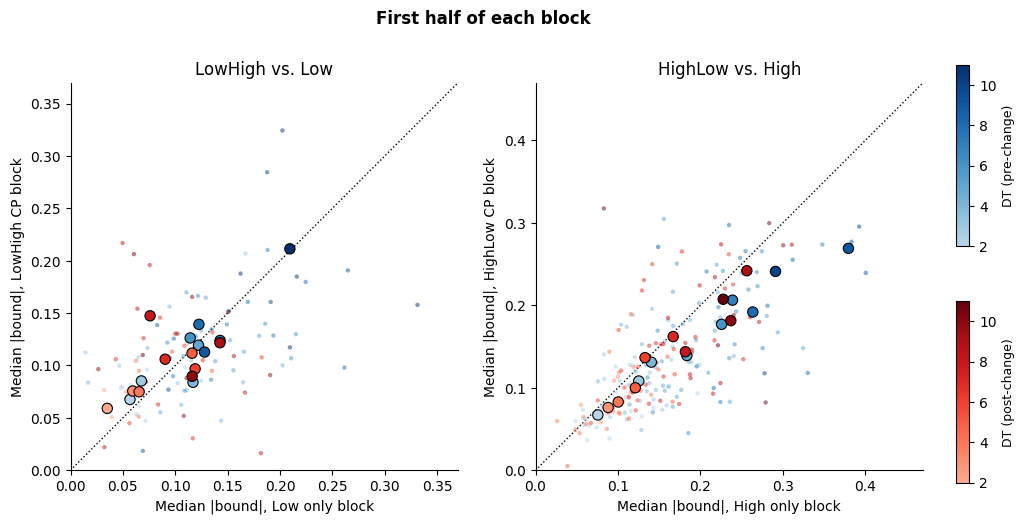

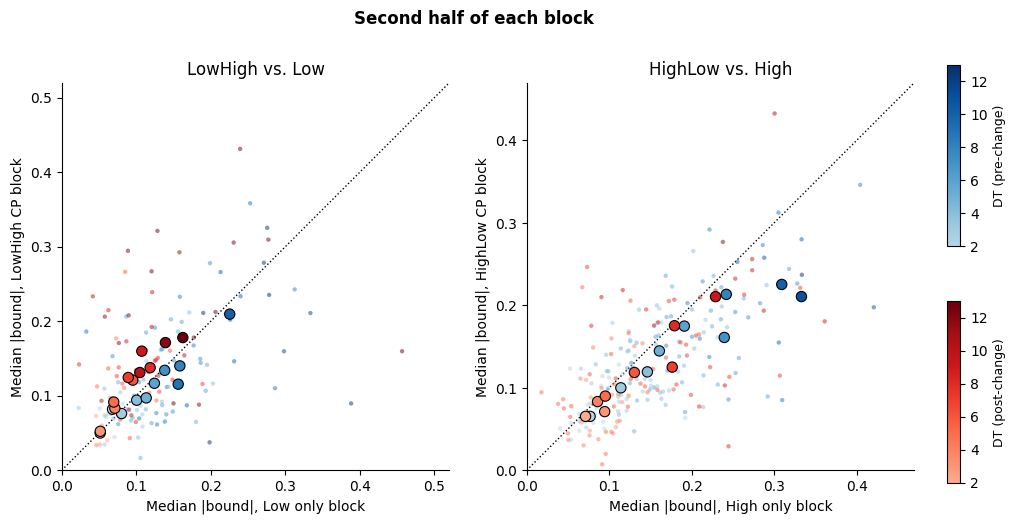

In [24]:
# ── Section 7 plot, split into first vs. second half of each participant's block ──
# Half is defined over ALL of a participant's trials in the block (not just the
# good ones), so it reflects position in the block rather than the quality filter.
_block_median_trial = _dt.groupby(['subject_index', 'block_index'])['trial_number'].transform('median')
_first_half = _dt['trial_number'] <= _block_median_trial

plot_bound_vs_dt(_first_half,  'First half of each block')
plot_bound_vs_dt(~_first_half, 'Second half of each block')


---
## Section 9 — Baseline-corrected pre/post change: CP block vs. fixed block

**Question**: does the bound change from pre- to post-change in a CP block differ from the
change seen between short and long trials in the matching fixed block?

Section 7 matches DT but compares *across* blocks (block order, SNR at decision). The plain
within-block pre-vs.-post test (Figure06's scratch section) stays within one block but
compares short (pre-change) with long (post-change) trials, and |bound| can depend on trial
length even without a strategy change. This section uses the fixed block's own short-vs.-long
difference as the baseline:

    Δ_CP    = post − pre           (CP block, split at the change point)
    Δ_fixed = long − short         (fixed block, split at the subject's median RT)
    test: Δ_CP − Δ_fixed = 0       (paired Wilcoxon across subjects)

The two splits are well matched: the task set each subject's change point online from the
median RT of that same fixed block. Same trial filter as Figure06 (`trial_number > 10`,
correct trials only).

**Remaining confounds**: post-change trials still end under the other SNR than the fixed
block's long trials, and the CP block still runs later in the session. The simulated
no-adaptation baseline in `Test_cpNullModel.ipynb` is what tells us how far from zero this
difference sits without any strategy change.


In [25]:
# ── Baseline-corrected pre/post change: CP (post − pre) vs. fixed (long − short) ──
_dt9 = _data_table_mxsc[(_data_table_mxsc['trial_number'] > 10) & (_data_table_mxsc['correct'] >= 0)]
_bs9 = get_bound_summaries_wcp(_dt9.reset_index(drop=True))
_subjects9 = np.sort(_dt9['subject_index'].dropna().unique())

def _wilcoxon_row(label, x):
    x = x[np.isfinite(x)]
    print(f'  {label:<22}{len(x):>4}{np.median(x):>+10.4f}{scipy.stats.wilcoxon(x).pvalue:>9.4f}')

print(f'  {"":<22}{"n":>4}{"median":>10}{"p":>9}')
for cp_name, fx_name, fx_block in [('LowHigh', 'Low', 1), ('HighLow', 'High', 2)]:
    cp, fx = np.asarray(_bs9[cp_name]), np.asarray(_bs9[fx_name])
    d_cp = cp[:, 1] - cp[:, 0]   # post − pre (CP block)
    d_fx = fx[:, 1] - fx[:, 0]   # long − short (fixed block, median-RT split)
    print(f'-- {cp_name} vs. {fx_name}')
    _wilcoxon_row(f'{cp_name} post − pre', d_cp)
    _wilcoxon_row(f'{fx_name} long − short', d_fx)
    _wilcoxon_row('difference', d_cp - d_fx)
    # How closely the two split points coincide
    med_rt = (_dt9[_dt9['block_index'] == fx_block].groupby('subject_index')['RT'].median()
              .reindex(_subjects9).to_numpy())
    gap = np.asarray(_bs9[f'CP{cp_name}']) - med_rt
    gap = gap[np.isfinite(gap)]
    print(f'  split points: CP step − fixed median RT, median {np.median(gap):+.1f} steps '
          f'(IQR {np.percentile(gap, 25):+.1f} to {np.percentile(gap, 75):+.1f})')


                           n    median        p
-- LowHigh vs. Low
  LowHigh post − pre      50   -0.0003   0.9771
  Low long − short        64   -0.0018   0.7686
  difference              50   -0.0005   0.4263
  split points: CP step − fixed median RT, median +0.0 steps (IQR +0.0 to +0.0)
-- HighLow vs. High
  HighLow post − pre      55   -0.0033   0.5575
  High long − short       61   +0.0094   0.0012
  difference              55   -0.0106   0.0008
  split points: CP step − fixed median RT, median +0.0 steps (IQR +0.0 to +0.0)


/Users/jigold/.cache/uv/archive-v0/Tz1O9i1auCqkh_VB/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
